**Bitácora · Chest pain NMF + PrefixSpan (fused)**

- **v1-v3** `Day1_nmf_v*`, `Day3_prefixspan_v*`  
  Separate Day 1 / Day 3 notebooks (untouched).
- **fused, full** `Chestpain_NMF_PrefixSpan_full` (2026-10-09) (untouched)  
  Part A = Day 1, Part B = Day 3 (no t-SNE / Table 1, no 3a, no 5a table, no token map). All events of each patient (no window).
- **fused, full, k=8** `Chestpain_NMF_PrefixSpan_full_k8` (2026-10-14) ← **this notebook**  
  Clone of `..._full` (same `codesets.yaml`, same concept-level tokens, outputs cleared) with `K_OVERRIDE = 8` and `VARIANT = 'full_k8'`, so every file it writes is labelled `full_k8` and the `k5_full` files are not overwritten. Purpose: compare it with `Chestpain_NMF_PrefixSpan_AHA` (codeset v2, group tokens, k=8) at the same k.


# Chest pain · NMF bundles and sequence motifs — full, k=8

**Part A (Day 1)**: events, bag of codes, NMF (k from the stability sweep), loadings, NMF-bundles table, components JSON.  
**Part B (Day 3)**: PrefixSpan motifs per bundle, stability, comparison groups, trajectory graph, final table.

Set `VARIANT`, `WINDOW_MONTHS` and (optionally) `K_OVERRIDE` in the next cell.

In [1]:
VARIANT       = 'full_k8'   # 'full' = every event of each person | 'win18' = events within 18 months before / after ANY chest pain event
WINDOW_MONTHS = None        # applied right after tagging (ethos_omop.window_around_anchor)
K_OVERRIDE    = 8          # None = the k chosen by the stability sweep (5 for this cohort); set an int to force it. 8 = the k the AHA run selected
ANCHOR        = 'chest_pain'
COHORT        = 'chestpain'
TAG           = f"{COHORT}_{VARIANT}"      # used in every cache / json / xlsx file name


# Part A · Day 1 — NMF bundles

## 0 · Getting the data

`ethos_omop.extract_cohort()` pulls the dx_9487 cohort: any patient carrying one of the
five R07.x codes, defined in `sql/chest_pain_cohort.sql`. It dumps the same shape
`extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both
`concept_id` and `source_concept_id` for every domain table, standard-named symlinks for
`meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of
  the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for
  ontology rollup (unspecified chest-pain codes to their parents, drugs to ingredients).

```python
import ethos_omop as eo
eo.extract_cohort("../sql/chest_pain_cohort.sql")   # -> ../data_input/
```

The next cell runs this once (150,368 patients, all real Ethos production data) and skips
it on every re-run once `../data_input/` exists.

Without Snowflake, or when you want data whose answer you already know:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through
`concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each
patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is
the whole problem this course is about, and every notebook here works either way.

*In plain terms: this is a one-time data export, like running a big report and saving the results as spreadsheets (CSV files) in a folder. Every cell below reads from that folder, not from Snowflake directly.*

In [2]:
import os
import ethos_omop as eo

OUT_DIR     = "../../inputs/chest_pain_cohort/"                     # extract_cohort() output, relative to repr_learn/
COHORT_SQL  = "../../sql/chest_pain_cohort.sql"   # relative to this notebook's cwd

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")

../../inputs/chest_pain_cohort// already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


### v2 · Visit pruning (care-driven bias)

The bundles from v1 reflect **care delivery, not condition**: pharmacy, office and ED visits are the
most common tokens and pull unrelated patients together. v2 changes one thing, at the load step
below: every event whose `domain` or `vocabulary_id` is "visit" is dropped before tagging.
Everything after it is unchanged, so v1 and v2 results are directly comparable.

Side effects to expect: the `ed_visit` codeset tag disappears (it sits on visit concepts), the
Table 1 `ed_visit` row reads 0%, and the proxy lookback window can shrink for patients whose first or
last record was a visit. The NMF fit is saved as `nmf_k{k}_chestpain_v2.npz`, so v1's file is not overwritten.


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=True)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (care-driven bias). A visit row is any row whose
# domain OR vocabulary is "visit"; pharmacy / office / ED visits otherwise dominate the bundles.
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visits   = raw[is_visit]
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets, token_level="concept", multi_group=True)

# ---- before / after pruning
tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients:               {raw.person_id.nunique():>10,} -> {events.person_id.nunique():,}")
print(f"distinct concepts:      {raw.concept_id.nunique():>10,} -> {events.concept_id.nunique():,}")
print(f"median events/patient:  {raw.groupby('person_id').size().median():>10,.0f} -> "
      f"{events.groupby('person_id').size().median():,.0f}")
print("\nremoved rows by vocabulary:")
print(visits['vocabulary_id'].value_counts().head(10).to_string())
print("\ntop removed visit concepts:")
print(visits['concept_name'].value_counts().head(10).to_string())

visit_ids = set(visits['concept_id'])
lost      = sorted(t for t, ids in codesets.items() if set(ids) & visit_ids)
print("\ncurated codeset tags that sit on visit concepts (their events are gone):", lost or "none")
vanished  = set(raw['person_id']) - set(events['person_id'])
if vanished:
    print(f"WARNING: {len(vanished):,} patients had only visit events and are no longer in `events`")
del raw, visits                                      # free memory; `events` is the pruned stream from here on

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)


beta_blocker        65 concepts   e.g. ['24 HR carvedilol phosphate 10 MG Extended Release Oral Capsule', '24 HR carvedilol phosphate 10 MG Extended Release Oral Capsule [Coreg]']
statin              43 concepts   e.g. ['amlodipine 10 MG / atorvastatin 10 MG Oral Tablet', 'amlodipine 10 MG / atorvastatin 20 MG Oral Tablet']
ssri                56 concepts   e.g. ['24 HR paroxetine hydrochloride 12.5 MG Extended Release Oral Tablet', '24 HR paroxetine hydrochloride 25 MG Extended Release Oral Tablet']
chest_pain           4 concepts   e.g. ['Chest pain', 'Chest pain on breathing']
anxiety             12 concepts   e.g. ['Adjustment disorder with mixed anxiety and depressed mood', 'Anxiety']
panic_attack         3 concepts   e.g. ['Agoraphobia without history of panic disorder', 'Panic disorder']
benzodiazepine      63 concepts   e.g. ['1 ML lorazepam 2 MG/ML Injection', '2 ML diazepam 5 MG/ML Auto-Injector']
gerd                 5 concepts   e.g. ['Gastro-esophageal reflux disease with 

,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,group,groups,in_codeset,tag
0,22,2212095,2019-04-25,Measurement,CPT4,80061,Lipid panel This panel must include the follow...,CPT4,CPT4/80061,NaN,NaN,False,lipid_panel_this_pan__cpt4__2212095
1,22,2212320,2019-04-25,Measurement,CPT4,82670,Estradiol; total,CPT4,CPT4/82670,NaN,NaN,False,estradiol_total__cpt4__2212320
2,22,2212816,2019-04-25,Measurement,CPT4,86376,"Microsomal antibodies (eg, thyroid or liver-ki...",CPT4,CPT4/86376,NaN,NaN,False,microsomal_antibodie__cpt4__2212816
3,22,4017355,2019-04-25,Measurement,SNOMED,104994008,"Triiodothyronine, free measurement",Procedure,SNOMED/104994008,NaN,NaN,False,triiodothyronine_fre__procedure__4017355
4,22,4068735,2019-04-25,Measurement,SNOMED,20436004,"Testosterone measurement, unbound",Procedure,SNOMED/20436004,NaN,NaN,False,testosterone_measure__procedure__4068735
5,22,4196731,2019-04-25,Measurement,SNOMED,313408009,Total thyroxine measurement,Procedure,SNOMED/313408009,NaN,NaN,False,total_thyroxine_meas__procedure__4196731


In [4]:
if WINDOW_MONTHS:
    _n0, _p0 = len(events), events.person_id.nunique()
    events = eo.window_around_anchor(events, ANCHOR, months=WINDOW_MONTHS)
    print(f"windowed to +/- {WINDOW_MONTHS} months around any {ANCHOR} event, merged per patient, exact duplicates dropped:")
    print(f"  events   {_n0:,} -> {len(events):,}")
    print(f"  patients {_p0:,} -> {events.person_id.nunique():,}")
    print(f"  median events per patient: {events.groupby('person_id').size().median():.0f}")
else:
    print(f"full variant: every event of each patient ({len(events):,} events, {events.person_id.nunique():,} patients)")


full variant: every event of each patient (46,525,784 events, 139,416 patients)


In [5]:
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file     rows     MB
master_condition_occurrence.csv 19065882 2786.8
    master_visit_occurrence.csv 17911768 2235.5
master_procedure_occurrence.csv 11560700 1711.5
         master_observation.csv  9803534 1208.7
         master_measurement.csv  8441761 1143.8
       master_drug_exposure.csv  7614270 1466.5
           concept_ancestor.csv  1109876   24.1
                     person.csv   139416   18.2
                    concept.csv    29658    3.8
                      death.csv       18    0.0


## 1 · Four decisions 

Read these before trusting anything downstream. Each is a modelling choice, not a detail.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

*In plain terms: medical coding systems (ICD, SNOMED, etc.) have multiple ways to say the same thing. "Standard concepts" is OMOP's canonical, de-duplicated version of each code — we only keep those, so the same diagnosis isn't double-counted under two different code spellings.*

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

*In plain terms: some medical codes look like numbers (e.g. `"0042"`) but aren't meant to be treated as one — turning them into an actual number silently drops the leading zero and corrupts the code.*

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

*In plain terms: claims data tells you "something happened on March 3rd," not "at 2:14pm." If five things happened the same day, we can't know their real order — so we pick one consistent order and are upfront that it's a guess, rather than pretending we have more precision than we do.*

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

*In plain terms: we only see what's in this data source. "This patient has no record of an anxiety diagnosis" might mean they truly don't have it, or it might just mean we started watching them too late to see it. Absence of a code is not proof of absence of the condition.*

count    139416.0
mean       2133.0
std        2390.0
min           0.0
25%        1863.0
50%        2285.0
75%        2475.0
max       99953.0


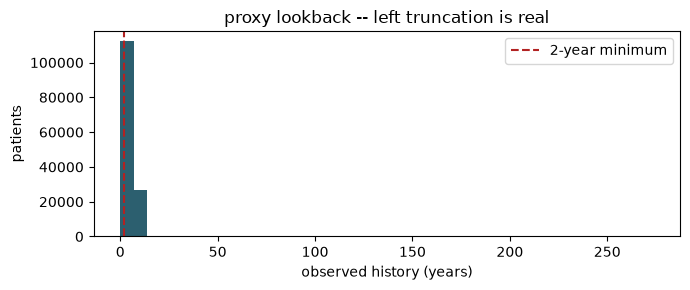


5558 patients (4.0%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [6]:
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

*In plain terms: instead of writing down a fixed list of magic numbers ("code 443698 means panic attack"), we write down a search pattern ("anything whose name matches panic_attack in the SNOMED vocabulary") and let the computer look up the matching codes every time. That way the same notebook keeps working even if the underlying code numbers differ between data sources.*

In [7]:
# Eyeball it: what did the "panic_attack" pattern actually match? Read
# straight from codesets.yaml (via eo.CODESETS) instead of retyping the
# patterns here, so this can't silently drift from what build_codesets()
# actually resolves.
pa_spec = eo.CODESETS['panic_attack']
eo.resolve(concept, pa_spec['patterns'], vocabularies=pa_spec.get('vocabularies'))

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
17905,4189538,Agoraphobia without history of panic disorder,SNOMED,61569007,Condition
13871,436074,Panic disorder,SNOMED,371631005,Condition
24827,4147466,Panic disorder with agoraphobia,SNOMED,35607004,Condition


In [8]:
# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
bz = codesets['benzodiazepine']
print("benzodiazepine concepts, direct:      ", len(bz))
print("benzodiazepine concepts, + descendants:", len(eo.expand_descendants(bz)))

# And roll an unspecified diagnosis UP to its parents -- directly useful for the
# unspecified chest pain codes (R07.8, R07.89) this whole cohort is built from.
cp = codesets['chest_pain']
print("chest pain parents, 1 level up:  ", len(eo.roll_up(cp, levels=1)))

benzodiazepine concepts, direct:       63
benzodiazepine concepts, + descendants: 63
chest pain parents, 1 level up:   4


In [9]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
venipuncture_for_blo__procedure__4102442    706804
essential_hypertensi__disorder__320128      681523
therapeutic_procedur__cpt4__2314284         633292
comprehensive_metabo__procedure__3661905    493339
complete_blood_count__procedure__4319466    491353
manual_therapy_techn__cpt4__2314290         469265
chest_pain__clinical_finding__77670         410204
lipid_panel_this_pan__cpt4__2212095         378338
low_back_pain__clinical_finding__194133     374177
type_2_diabetes_mell__disorder__201826      325714
chiropractic_manipul__cpt4__2314331         305693
neck_pain__clinical_finding__24134          297623
hemoglobin_a1c_measu__procedure__4184637    296668
general_examination___procedure__4036803    296482
therapeutic_activiti__cpt4__2314294         290828

tagged into a codeset: 9.2%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

*In plain terms: we only defined clinical labels (chest_pain, anxiety, panic_attack, ekg, ...) for the codes relevant to this specific question. Everything else in a patient's record still exists in the data, we just haven't given it a friendly name -- it isn't lost, and it's part of what later, more automated methods (Day 4's embeddings) can pick up on that our hand-picked labels can't.*

## 3 · The bag of codes, and the exact failure

In [10]:
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :10]

/Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/ethos_omop.py:588: PerformanceWarning: The following operation may generate 2153837784 cells in the resulting pandas object.
  X    = pd.crosstab(sub["person_id"], sub[col])


(139416, 15449)


tag,005_ml_afliberceptay__quant_branded_drug__1735886,007_ml_aflibercept_1__quant_branded_drug__747804,025_mg_05_mg_dose_15__branded_drug__793152,025_mg_05_mg_dose_3___branded_drug__741834,02_ml_glucagon_5_mgm__quant_branded_drug__37499704,02_ml_methotrexate_5__quant_branded_drug__45776920,02_ml_sarscov2_covid__quant_branded_drug__37355138,036_ml_follitropin_b__quant_branded_drug__43011837,03_ml_bremelanotide___quant_branded_drug__1361652,03_ml_enoxaparin_sod__quant_clinical_drug__40160970
person_id,,,,,,,,,,
22,0,0,0,0,0,0,0,0,0,0
50,0,0,0,0,0,0,0,0,0,0
67,0,0,0,0,0,0,0,0,0,0
68,0,0,0,0,0,0,0,0,0,0
321,0,0,0,0,0,0,0,0,0,0


**Goal:** get a feel for `X` before we do anything clever with it — which codes are common, which are rare, and how that's different from what an NMF component (two sections down) will tell us.

Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `chest_pain` is ~100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

*In plain terms: "prevalence" here just means "what % of patients have this code at all." That's a different question from "which codes define this cluster/component" -- a code can be common across the whole cohort (like `chest_pain`, since that's how the cohort was defined) without being distinctive of any particular subgroup.*

15449 codes, prevalence range 0.001% - 95.966%


,prevalence
tag,
chest_pain__clinical_finding__77670,96.0%
venipuncture_for_blo__procedure__4102442,72.3%
comprehensive_metabo__procedure__3661905,68.4%
complete_blood_count__procedure__4319466,67.9%
lipid_panel_this_pan__cpt4__2212095,64.0%
general_examination___procedure__4036803,58.3%
hemoglobin_a1c_measu__procedure__4184637,52.1%
electrocardiogram_ro__cpt4__2313816,49.7%
electrocardiogram_ro__cpt4__2313814,47.6%


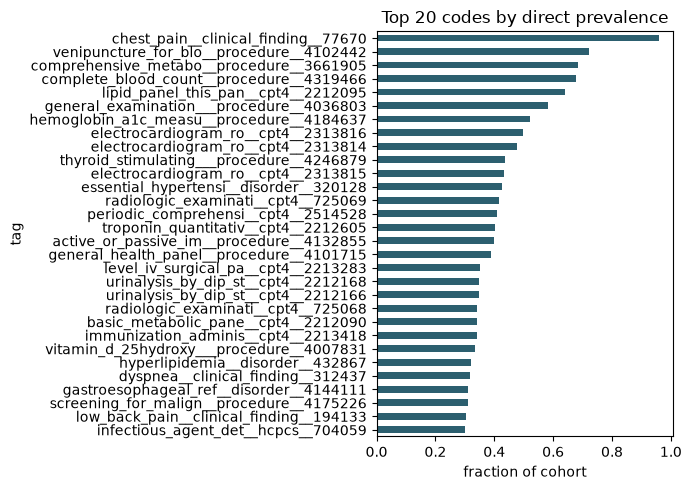

In [11]:
prevalence = X.mean().sort_values(ascending=False)
print(f"{len(prevalence)} codes, prevalence range "
      f"{prevalence.min():.3%} - {prevalence.max():.3%}")
display(prevalence.head(30).to_frame('prevalence').style.format('{:.1%}'))

plt.figure(figsize=(7, 5))
prevalence.head(30).iloc[::-1].plot.barh(color='#2C5F6F')
plt.xlabel('fraction of cohort'); plt.title('Top 20 codes by direct prevalence')
plt.tight_layout(); plt.show()

### Choosing `min_count` from prevalence

`bag_of_codes(min_count=...)` drops a code unless it has at least that many **events** in the
whole cohort, so one patient with 20 refills can keep a code alive. What actually limits a
model is how many **patients** carry a code, so this cell works in patients.

*In plain terms: a code seen in only a handful of patients can't form a reliable pattern, but
dropping too many codes throws away real signal. This table shows, for each cutoff, how many
columns survive and how much of the patient-by-code information is kept, then suggests a
cutoff.*

The suggested floor is the number of patients a code needs so that a training split is
expected to contain at least `MIN_TRAIN_PATIENTS` of them: `ceil(MIN_TRAIN_PATIENTS * cohort /
N_TRAIN)`. It scales with cohort size. It is a heuristic, not a statistical test, and it works
on `events`, so it does not need the full matrix (which would be too large to build with no
cutoff).

,prevalence_%,columns,pairs_kept_%
rule,,,
>= 1 patients,0.0007,27743,100.00
>= 2 patients,0.0014,22644,99.96
>= 5 patients,0.0036,17660,99.86
>= 10 patients,0.0072,14562,99.70
>= 20 patients,0.0143,11674,99.40
>= 35 patients,0.0251,9546,98.98
>= 50 patients,0.0359,8326,98.60
>= 100 patients,0.0717,6253,97.50
>= 200 patients,0.1435,4613,95.75


cohort 139416 patients, training split 20000
suggested floor: 35 patients (0.025% prevalence) -> 9546 of 27743 columns, 99.0% of patient-code pairs kept
codeset tags below the floor: none


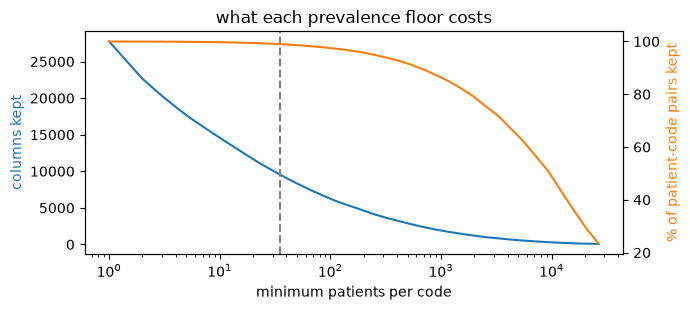


To apply it, build X from the kept codes only (min_count=1 on pre-filtered events):
    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)


In [12]:
import math

MIN_TRAIN_PATIENTS = 5            # a code should appear in >= this many patients of a training split
n_pat   = events.person_id.nunique()
N_TRAIN = min(20_000, int(0.6 * n_pat))      # training-split size used by the k-sweep cells

# patients per code, and events per code (what bag_of_codes' min_count counts)
code, tags = pd.factorize(events['tag'])
key        = events['person_id'].to_numpy(np.int64) * len(tags) + code
prev_pat   = pd.Series(np.bincount(np.unique(key) % len(tags), minlength=len(tags)), index=tags)
ev_cnt     = pd.Series(np.bincount(code, minlength=len(tags)), index=tags)
all_pairs  = int(prev_pat.sum())             # distinct (patient, code) pairs = ones in the full 0/1 matrix

def summarize(mask):
    return {'columns': int(mask.sum()),
            'pairs_kept_%': round(100 * prev_pat[mask].sum() / all_pairs, 2)}

rows = [{'rule': f'>= {p} patients', 'prevalence_%': round(100 * p / n_pat, 4), **summarize(prev_pat >= p)}
        for p in [1, 2, 5, 10, 20, 35, 50, 100, 200, 500]]
rows.append({'rule': 'current min_count=20 (events)', 'prevalence_%': np.nan, **summarize(ev_cnt >= 20)})
rule_tbl = pd.DataFrame(rows).set_index('rule')

MIN_PATIENTS = math.ceil(MIN_TRAIN_PATIENTS * n_pat / N_TRAIN)
KEEP_TAGS    = prev_pat.index[prev_pat >= MIN_PATIENTS]
display(rule_tbl)

# the clinical (codeset) tags are the ones the analysis is about -- do any fall below the floor?
codeset_tags = [t for t in codesets if t in prev_pat.index]
lost = prev_pat[codeset_tags][lambda s: s < MIN_PATIENTS]
print(f"cohort {n_pat} patients, training split {N_TRAIN}")
print(f"suggested floor: {MIN_PATIENTS} patients ({100 * MIN_PATIENTS / n_pat:.3f}% prevalence) -> "
      f"{len(KEEP_TAGS)} of {len(prev_pat)} columns, "
      f"{100 * prev_pat[KEEP_TAGS].sum() / all_pairs:.1f}% of patient-code pairs kept")
print("codeset tags below the floor:", lost.to_dict() if len(lost) else "none")

fig, ax = plt.subplots(figsize=(7, 3.2))
ps = np.unique(np.round(np.geomspace(1, max(2, prev_pat.max() / 5), 40)).astype(int))
ax.plot(ps, [(prev_pat >= p).sum() for p in ps], color='C0')
ax.set_xscale('log'); ax.set_xlabel('minimum patients per code'); ax.set_ylabel('columns kept', color='C0')
ax2 = ax.twinx()
ax2.plot(ps, [100 * prev_pat[prev_pat >= p].sum() / all_pairs for p in ps], color='C1')
ax2.set_ylabel('% of patient-code pairs kept', color='C1')
ax.axvline(MIN_PATIENTS, ls='--', c='grey')
ax.set_title('what each prevalence floor costs')
plt.tight_layout(); plt.show()

print("\nTo apply it, build X from the kept codes only (min_count=1 on pre-filtered events):")
print("    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)")

In [13]:
X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
print(X.shape)

(139416, 9546)


In [14]:
# Two dx_9487 patients with a near-IDENTICAL bag of codes and opposite triage answers.
weak = eo.chest_pain_labels(events)                 # rule-based probe labels: psych vs cardiac
lab  = weak.set_index('person_id').chest_pain_label

_eg = events[events.groups.notna()]
Xg = eo.bag_of_codes(_eg.assign(group=_eg.groups.astype(str).str.split('|')).explode('group').reset_index(drop=True), col='group', min_count=1)   # group-level checklist (a concept counts in EVERY group it is in), demo only
both = [p for p in X.index
        if Xg.loc[p].get('chest_pain', 0) == 1
        and Xg.loc[p].get('ekg', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'psych'),   None)
b = next((p for p in both if lab[p] == 'cardiac'), None)
assert a and b, ("No matching-bag pair found in this sample. Widen the `both` filter, "
                 "or inspect `both` to see which side is missing.")

print("bag-of-codes view -- indistinguishable on chest_pain + ekg alone:")
display(Xg.loc[[a, b], ['chest_pain', 'ekg']])

print("\nactual timelines -- obviously different:")
FOCUS = ['chest_pain', 'ekg', 'anxiety', 'panic_attack', 'ssri', 'benzodiazepine',
         'troponin', 'stress_test', 'coronary_angio', 'cad']
for pid in (a, b):
    s = events[(events.person_id == pid) & eo.group_mask(events, FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'groups', 'tag']].drop_duplicates('tag').to_string(index=False))

chest_pain patients: 139416   labelled: 65235   both-evidence (dropped): 37617   no-evidence (dropped): 36564
bag-of-codes view -- indistinguishable on chest_pain + ekg alone:


group,chest_pain,ekg
person_id,,
410,1,1
389,1,1



actual timelines -- obviously different:

  person_id 410  (psych)
event_date     groups                                             tag
2020-04-08        ekg             electrocardiogram_ro__cpt4__2313814
2020-05-12    anxiety              anxiety_disorder__disorder__442077
2021-10-13 chest_pain             chest_pain__clinical_finding__77670
2021-11-23    anxiety          generalized_anxiety___disorder__434613
2022-05-03 chest_pain chest_pain_on_breath__clinical_finding__4168213

  person_id 389  (cardiac)
event_date     groups                                 tag
2023-06-29 chest_pain chest_pain__clinical_finding__77670
2025-09-30        ekg electrocardiogram_ro__cpt4__2313815
2025-09-30   troponin troponin_quantitativ__cpt4__2212605


**That is the motivation for the whole week.** Near-identical features, opposite triage
answer. The information lives in the order and the surrounding evidence, and a flat bag of
codes throws both away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

*In plain terms: this isn't a case of "use a fancier algorithm and it'll figure it out." The bag-of-codes table literally does not contain the information needed to tell these two patients apart -- both rows are 1, 1. No amount of machine learning can pull a distinction out of data where the distinction was never recorded in the first place. You have to fix the representation, not the model.*

### On `chest_pain_labels()`

There is no adjudicated ground truth for "was this actually cardiac." `chest_pain_labels()`
builds probe labels from **corroborating co-evidence only** — anxiety/panic diagnoses,
SSRIs, or benzodiazepines on the `psych` side; troponin, stress tests, coronary
angiography, or a CAD diagnosis on the `cardiac` side. Patients with both kinds of
evidence, or neither, are dropped, and the counts are printed so you can see how many.

*In plain terms: instead of guessing the reason for the chest pain directly, we look for other, more specific evidence nearby — did the patient also have an anxiety/panic diagnosis or an SSRI/benzodiazepine prescription? Did they also have a troponin, stress test, or coronary angiography? If the evidence points clearly one way, we use that as the label. If it points both ways, or neither way, we honestly say "we don't know" and drop them rather than force a guess.*

**The time order is deliberately not used here.** If you labelled by "anxiety dx before
chest pain code" and then tested whether the order predicts the label, you'd get perfect
accuracy by construction and learn nothing. Days 3-4 test order directly — the label has to
stay independent of it, or the test is circular.

*In plain terms: it would be tempting to say "anxiety diagnosis came before the chest pain code, so it must be psych-related." But that's using the very thing we're trying to test (timing) to build the answer key -- then "discovering" that timing predicts the answer would be circular, not a real finding. So the answer key is built from a different, independent kind of evidence, and timing is only used afterward to see if it can predict that answer.*

In [15]:
from sklearn.metrics import pairwise_distances
import scipy.sparse as sp

# chest_pain is the cohort anchor -- ~100% prevalence here, so it's a near-
# constant column that carries no discriminative signal and would just eat a
# component. Drop it before any distance/SVD/NMF fit; X itself (with the
# column) stays untouched for the two-patient demo above and Table 1 below.
# Everything downstream works on a SPARSE copy (Xs): same values as the dense matrix without the
# anchor column, a fraction of the memory, and faster NMF / SVD. No dense copy without
# `chest_pain` is ever built.
nmf_cols = X.columns[~X.columns.isin(events.loc[eo.group_mask(events, 'chest_pain'), 'tag'])]                  # code names for the components
n_pat    = X.shape[0]
Xs = sp.csr_matrix(X.to_numpy())[:, X.columns.get_indexer(nmf_cols)].astype(float).tocsr()
print(f"Xs {Xs.shape}, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%}")

def dist_to_all(row, M, metric, chunk=10_000):
    """Distances from one row to every row of sparse M, densifying only `chunk` rows at a time."""
    return np.concatenate([pairwise_distances(row, M[i:i + chunk].toarray(), metric=metric)[0]
                           for i in range(0, M.shape[0], chunk)])

sub = Xs[:400].toarray()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

pos = list(X.index).index(a)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = dist_to_all(Xs[pos:pos+1].toarray(), Xs, m)
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")

Xs (139416, 9542), density 0.978%
cosine     mean=0.881  sd=0.066


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


jaccard    mean=0.942  sd=0.036

cosine     neighbours of 410: ['?', '?', '?', '?', 'cardiac']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric ja

jaccard    neighbours of 410: ['?', '?', '?', '?', 'cardiac']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

*In plain terms: a patient with 200 recorded codes isn't automatically "less similar" to everyone else than a patient with 20 codes — but a naive distance metric (Euclidean) treats it that way, because it's sensitive to how many codes are turned on, not just which ones. Cosine distance cares about the pattern of codes, not the raw count, which is what we actually want to compare.*

## 5 · The curse of dimensionality

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

*In plain terms: with only a handful of columns, "similar" and "different" are easy to tell apart. Once you have tens of thousands of columns and each patient only has a handful of them turned on, almost every pair of patients ends up looking roughly equally (dis)similar to each other -- there's no longer a meaningful "close" versus "far." This is a general math fact (the "curse of dimensionality"), not something specific to our data.*

In [16]:
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 6 · Truncated SVD and NMF

**Goal:** compress thousands of sparse code columns down into a handful of numbers per patient that are actually usable for distance/clustering/visualization — and see two different ways of doing that compression.

*In plain terms: both methods below take the wide, sparse `X` table (thousands of mostly-zero columns) and produce a much narrower table (a few dozen columns) that still captures most of the real signal. Think of it as automatic summarization of a patient's code history into a small number of "themes." SVD and NMF differ in what kind of themes they're allowed to produce -- that difference is exactly why we look at both.*

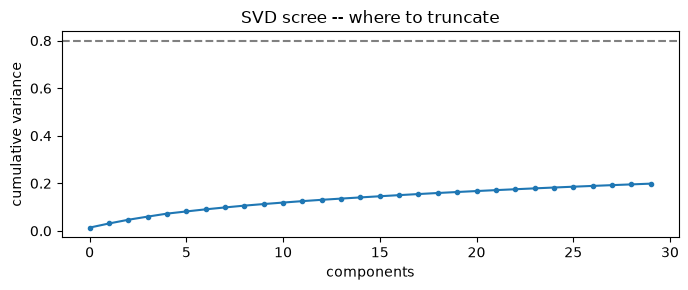

In [17]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

Xn  = normalize(Xs)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(30, Xs.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

### NMF and Choosing k for the NMF

The k=12 above was chosen by reading the components. This sweep adds numbers for it, the
NMF counterpart of Day 2's elbow + silhouette + bootstrap-ARI table for KMeans.

*In plain terms: fit the NMF at several values of k and, for each one, check how well it
explains patients it was never fit on, how well separated the resulting patient groups are
(silhouette), and whether the same bundles come back on re-draws. Then pick a k where adding
more components stops paying for itself but the bundles are still reproducible.*

Every k is fit on the same `N_SWEEP` training patients and scored on a disjoint `N_HELD`
held-out set, so the comparison is fair and the error is not just training fit. The
silhouette is computed in the SVD space (`Z`) that Day 2 used for KMeans, not in NMF's own
loading space, which would be circular because those loadings defined the groups.

The whole sweep is repeated on every split in `SPLIT_SEEDS` (independent random train / held-out
splits of the cohort), each with `N_BOOT_K` bootstrap refits per k. More refits only sharpen the
estimate within one split. Several splits show whether a k looks stable only because of the
patients it happened to see. Every NMF fit in this section uses the same settings (`NMF_KW`,
defined in the stability cell), so the base fit and its refits are converged the same way.

The fits run in parallel (`N_JOBS` workers, because sklearn's NMF uses one core per fit) on a
sparse copy of the matrix, `Xs`. The result is the same as the dense serial version; it is only
faster and much smaller in memory.

In [18]:

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score
import time

# one place for the NMF fit settings, used by every NMF fit in this section
NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)

N_BOOT        = 10        # refits; each is a full NMF fit, raise once you know the runtime
N_BOOT_SAMPLE = 20_000    # patients per resample (capped at the cohort size)
N_EVAL        = 20_000    # fixed patients used to compare argmax labels across refits

def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_BOOT, n_sample=N_BOOT_SAMPLE,
                  n_eval=N_EVAL, seed=0):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's
    components are matched to the base fit's by cosine similarity (Hungarian
    algorithm). ARI compares argmax patient partitions, which needs no matching.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(Xv.shape[0], min(n_eval, Xv.shape[0]), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari = [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(Xv.shape[0], min(n_sample, Xv.shape[0]), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows, cols = linear_sum_assignment(-S)          # rows come back sorted 0..k-1
        cos.append(S[rows, cols])                       # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  "
              f"ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari)

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  50 out of  60 | elapsed:  2.9min remaining:   34.5s


60 jobs on 12 workers; summed fit time 35.9 CPU-min


[Parallel(n_jobs=12)]: Done  60 out of  60 | elapsed:  3.2min finished


,held_out_err,silhouette,ari_mean,ari_sd_splits,n_splits_solid,n_splits_sugg,cos_mean,n_unstable,n_used
k,,,,,,,,,
3,0.897,0.063,0.868,0.034,5,5,0.995,0.0,3
4,0.891,0.063,0.880,0.040,5,5,0.999,0.0,4
5,0.886,0.061,0.861,0.079,5,5,0.998,0.0,5
6,0.882,0.055,0.718,0.061,2,5,0.924,0.0,6
7,0.879,0.050,0.676,0.068,1,5,0.943,1.0,7
8,0.875,0.048,0.712,0.081,2,5,0.978,0.0,8
9,0.873,0.047,0.717,0.090,3,4,0.950,1.0,9
10,0.870,0.048,0.631,0.029,0,4,0.901,2.0,10
11,0.867,0.047,0.679,0.039,0,5,0.938,1.0,11


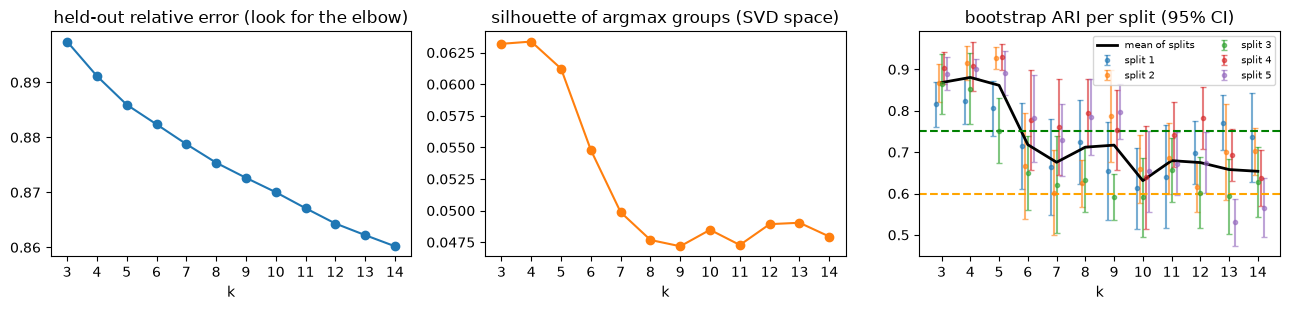

largest k with ARI >= 0.60 on 4+ of 5 splits and mean cos >= 0.75: 14
largest k with ARI >= 0.75 on 4+ of 5 splits and no unstable component (median): 5


In [19]:
import time
import io, contextlib
import os, math
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.metrics import silhouette_score
from scipy import stats

K_GRID      = list(range(3, 15))
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent train / held-out splits of the cohort
N_SWEEP     = 20_000      # train patients every k is fit on
N_HELD      = 10_000      # disjoint held-out patients for error / silhouette
N_BOOT_K    = 10          # bootstrap refits per k and split (reuses nmf_stability above)
NC_SIL      = min(24, Z.shape[1])   # SVD dims Day 2 scored KMeans silhouette in
MIN_SPLITS_OK = math.ceil(0.8 * len(SPLIT_SEEDS))   # a k must pass on this many splits (4 of 5)
N_JOBS      = max(1, (os.cpu_count() or 2) - 2)   # sklearn's NMF is single-threaded: one fit per core

def rel_err(X, W, H):
    """||X - W H||_F / ||X||_F without building the dense W @ H (X may be sparse)."""
    x2    = X.multiply(X).sum() if sp.issparse(X) else (X ** 2).sum()
    cross = np.sum((X @ H.T) * W)
    quad  = np.sum((W.T @ W) * (H @ H.T))
    return float(np.sqrt(max(x2 - 2 * cross + quad, 0.0) / x2))

def sweep_job(split_seed, k, Xtr, Xho, Zho, n_boot):
    """All metrics for one (split, k): one base fit plus n_boot bootstrap refits."""
    t0 = time.perf_counter()
    m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
    Wh = m.transform(Xho)
    lab_ho = Wh.argmax(1)
    with contextlib.redirect_stdout(io.StringIO()):          # silence per-boot prints
        cos, ari = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=Xtr.shape[0],
                                 n_eval=Xtr.shape[0], seed=k)
    share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
    return {'split': split_seed, 'k': k,
            'held_out_err': rel_err(Xho, Wh, m.components_),
            'silhouette': silhouette_score(Zho, lab_ho) if len(set(lab_ho)) > 1 else np.nan,
            'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1),
            'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
            'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
            'n_used': int((share >= .01).sum()), 'secs': time.perf_counter() - t0}

def make_split(split_seed):                                   # sliced once here, so workers get small inputs
    perm   = np.random.default_rng(split_seed).permutation(Xs.shape[0])
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    return Xs[tr], Xs[ho], Z[ho, :NC_SIL]                     # Z rows align with Xs rows

splits  = {s: make_split(s) for s in SPLIT_SEEDS}
jobs    = [(s, k) for k in sorted(K_GRID, reverse=True) for s in SPLIT_SEEDS]   # slow (large k) first
results = Parallel(n_jobs=N_JOBS, verbose=5)(
              delayed(sweep_job)(s, k, *splits[s], N_BOOT_K) for s, k in jobs)
res       = pd.DataFrame(results)
per_split = {s: res[res.split == s].drop(columns=['split', 'secs']).set_index('k').sort_index()
             for s in SPLIT_SEEDS}
print(f"{len(jobs)} jobs on {N_JOBS} workers; summed fit time {res.secs.sum() / 60:.1f} CPU-min")

# one row per k, summarised over splits
g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(), 'silhouette': g.silhouette.mean(),
                      'ari_mean': g.ari_mean.mean(), 'ari_sd_splits': g.ari_mean.std(),
                      'n_splits_solid': g.ari_mean.apply(lambda a: int((a >= .75).sum())),
                      'n_splits_sugg':  g.ari_mean.apply(lambda a: int((a >= .60).sum())),
                      'cos_mean': g.cos_mean.mean(), 'n_unstable': g.n_unstable.median(),
                      'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o')
ax[0].set_title('held-out relative error (look for the elbow)')
ax[1].plot(sweep.index, sweep.silhouette, marker='o', color='C1')
ax[1].set_title('silhouette of argmax groups (SVD space)')
for i, s in enumerate(SPLIT_SEEDS):                          # small x-offset so splits do not overlap
    d = per_split[s]
    ax[2].errorbar(d.index + (i - (len(SPLIT_SEEDS) - 1) / 2) * 0.1, d.ari_mean,
                   yerr=t_crit * d.ari_se, fmt='o', ms=3, capsize=2, alpha=.6, label=f'split {s}')
ax[2].plot(sweep.index, sweep.ari_mean, 'k-', lw=2, label='mean of splits')
ax[2].axhline(0.75, ls='--', c='green');  ax[2].axhline(0.60, ls='--', c='orange')
ax[2].set_title('bootstrap ARI per split (95% CI)'); ax[2].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.n_splits_sugg >= MIN_SPLITS_OK) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.n_splits_solid >= MIN_SPLITS_OK) & (sweep.n_unstable == 0)]
print(f"largest k with ARI >= 0.60 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and mean cos >= 0.75:",
      int(ok.index.max()) if len(ok) else "none")
print(f"largest k with ARI >= 0.75 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and no unstable component (median):",
      int(strong.index.max()) if len(strong) else "none")

### Reading the k sweep

- **Silhouette** is the KMeans-style number: how much closer each held-out patient is to
  their own `argmax` group than to the next nearest one, in the same SVD space Day 2 scored
  KMeans in. Closer to 1 is better. Expect it to be **low in absolute terms** (NMF groups are
  soft themes, not tight blobs) and to **fall as k grows**, so read the *shape*, not the
  level.
- **Held-out error** always falls as k grows, so the *elbow* is what matters, not the minimum.
- **ARI / cos** are the same bootstrap checks as above, now per k and per split. `ari_mean` is
  the average over splits and `ari_sd_splits` its spread; `n_splits_solid` / `n_splits_sugg` count
  the splits with ARI at or above 0.75 / 0.60. `n_unstable` is the median over splits. Stability
  usually decays as k rises; the largest k that still passes is an upper bound.
- **Same ranking on most splits:** the pattern belongs to k, not to the patients drawn. Prefer
  the largest k that is solid on at least 4 of 5 splits (`MIN_SPLITS_OK`). **Splits disagree
  (large `ari_sd_splits`), or neighbouring k overlap within their 95% intervals:** stability
  cannot separate them, so choose on clinical readability and keep the "suggestive" caveat on
  any k below 0.75.
- Compare k by the interval (`ari_se`), not by `ari_sd`. `ari_sd` is the spread across refits
  and does not shrink with more refits; `ari_se` does.
- **`n_used`** counts components that are the dominant component for at least 1% of held-out
  patients. A k where `n_used` stops growing is adding redundant or dead components.
- No single column picks k. A defensible k sits **after the error elbow and before stability
  collapses**, with a silhouette not much worse than its neighbours. The final check is still
  whether the extra components read as distinct clinical bundles, as in the k=12 discussion.

### Are those 11 components stable? Bootstrap validation of the NMF
Now let's focus on looking stability within K=11
*In plain terms: re-run the NMF on random re-draws of the patients and see whether the same
code bundles show up. A bundle that keeps reappearing is real structure; one that only
appears for some draws is an accident of which patients were sampled.*

NMF component numbering is arbitrary between fits (component 3 in one run may be component 7
in the next), so each refit's components are first **matched** to the base fit's by cosine
similarity. Two outputs:

1. **Per component:** matched cosine between the base bundle and its refit counterpart.
2. **Cohort level:** ARI between the `argmax` patient labels, comparable with Day 2.

### Reading the stability table for K=11

- **`cos_mean` near 1** means the component's code bundle reappears almost unchanged in every
  resample. **Low `cos_mean` or high `cos_sd`** means the bundle depends on which patients
  happened to be drawn, so don't build a rule on it.
- The cosine cut-offs (0.90 solid, 0.75 suggestive) are working heuristics, not standards.
- **Bootstrap ARI** compares the `argmax` patient labels from each refit with the base
  labels, so it is directly comparable with Day 2's KMeans bootstrap ARI (0.75 solid, 0.60
  suggestive). A component can be stable as a *bundle* while the `argmax` *labels* are
  noisy, because soft loadings tie between bundles. High cos with low ARI is that case.
- Each refit sees only `N_BOOT_SAMPLE` patients, fewer than the base fit's full cohort, so
  this is a slightly pessimistic stability estimate.
- This validates stability, not meaning. Whether component 2 really is "cardiac workup" is
  still the read-the-top-codes judgement above.

### Final Bundles for K=11

In [20]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
#
# In plain terms: NMF is only allowed to add codes together, never subtract
# them, so each component ends up looking like "a bundle of codes that tend
# to show up together" -- e.g. "anxiety + benzodiazepine" reads as an actual
# clinical bundle, not an abstract direction in space. That's why we print
# the top-10 codes per component below: it's how you check whether a
# component actually means something clinically, or is noise.

for k in [K_OVERRIDE or int(strong.index.max())]:
#for k in [11]:
    nmf = NMF(n_components=k, **NMF_KW).fit(Xs)
    H   = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab_k = nmf.transform(Xs).argmax(axis=1)
    dom = pd.Series(lab_k).value_counts().sort_index()
    # save the fit for reuse (Day 3 loads it instead of refitting); the tag keeps cohorts apart
    np.savez(f"nmf_k{k}_{TAG}.npz", H=H.to_numpy(), cols=np.array(H.columns, dtype=str),
             pids=X.index.to_numpy(), labels=lab_k)
    print (f"\nNMF with {k} components:")
    for c in range(k):
        n    = int(dom.get(c, 0))
        row  = H.iloc[c]
        top  = row.sort_values(ascending=False).head(10)
        share = (top / row.sum() * 100).round(1)
        # codes = [f"{name} ({pct}%)" for name, pct in share.items()]
        codes = [f"{name}" for name, pct in share.items()]
        print(f"component {c} (n={n}, {n / n_pat * 100:.1f}%): {codes}")


NMF with 8 components:
component 0 (n=20392, 14.6%): ['troponin_quantitativ__cpt4__2212605', 'electrocardiogram_ro__cpt4__2313815', 'electrocardiogram_ro__cpt4__2313816', 'radiologic_examinati__cpt4__725068', 'complete_blood_count__procedure__4319466', 'comprehensive_metabo__procedure__3661905', 'ddimer_assay_quantit__procedure__4015482', 'venipuncture_for_blo__procedure__4102442', 'basic_metabolic_pane__cpt4__2212090', 'magnesium_measuremen__procedure__4243005']
component 1 (n=13487, 9.7%): ['gynecologic_examinat__procedure__4306780', 'infectious_agent_det__cpt4__2213162', 'infectious_agent_det__cpt4__2213115', 'urine_pregnancy_test__procedure__4014769', 'cytopathology_cervic__cpt4__2213244', 'infectious_agent_det__cpt4__46257666', 'bacterial_culture_ur__procedure__4016363', 'transvaginal_echogra__procedure__4027510', 'infectious_agent_det__cpt4__44816441', 'general_examination___procedure__4036803']
component 2 (n=44564, 32.0%): ['general_examination___procedure__4036803', 'lipid_pa

**NMF bundles as a table** — one row per component for the underwriter review: n (%), the top-5 OMOP entities (name, vocabulary + code, concept_id, share of the bundle's patients) and two empty columns to fill in (pathway, UW suggestion). Written to `nmf_components_<cohort>_k<k>_v3.xlsx`. `RANK_BY = 'prevalence'` ranks by how many of the bundle's patients have the code instead of by NMF loading.

In [21]:
COHORT = 'chestpain'
# Export the NMF components as a table to review with the underwriters: one row per bundle, the last two columns are left empty to fill in.
import re
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

RANK_BY = 'loading'        # 'loading' = codes that define the bundle (NMF loading); 'prevalence' = codes most patients of the bundle have
TOP_N   = 5
k_exp   = nmf.n_components_
XLSX_NMF = f"nmf_components_{COHORT}_k{k_exp}_{VARIANT}.xlsx"

lab_e  = nmf.transform(Xs).argmax(1)                                   # dominant component per patient (same rule as the sizes above)
Hc     = pd.DataFrame(nmf.components_, columns=nmf_cols)
meta   = events.drop_duplicates('tag').set_index('tag')

def entity(tok, prev):
    r = meta.loc[tok]
    name = re.split(r' \(|;| This ', str(r.concept_name))[0].strip()
    name = name if len(name) >= 8 else str(r.concept_name)          # packs like '{6 (azithromycin ...) } Pack [Z-PAK]' would be cut to '{6'
    name = name if len(name) <= 60 else name[:60].rsplit(' ', 1)[0] + '…'
    return f"{name} [{r.vocabulary_id} {r.concept_code}] (concept_id {int(r.concept_id)}; {prev:.0%} of bundle)"

rows_e = []
for c in range(k_exp):
    members = np.flatnonzero(lab_e == c)
    prev  = pd.Series(np.asarray(Xs[members].mean(axis=0)).ravel(), index=nmf_cols)     # share of the bundle's patients with each code
    score = Hc.iloc[c] if RANK_BY == 'loading' else prev
    top   = score.nlargest(TOP_N).index
    rows_e.append({'Group (bundle)': f"c{c}",
                   'n (%)': f"{len(members):,} ({len(members) / len(lab_e):.1%})",
                   'Most frequently OMOP clinical entities found': "\n".join(f"{i}. {entity(t, prev[t])}" for i, t in enumerate(top, 1)),
                   'Suggested Clinical Pathway': '',
                   'UW suggestion': ''})
nmf_table = pd.DataFrame(rows_e)

F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'NMF k={k_exp}'
ws.append(list(nmf_table.columns))
for j in range(1, ws.max_column + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 30
for row in nmf_table.itertuples(index=False):
    ws.append(list(row))
for i in range(2, len(nmf_table) + 2):
    ws.row_dimensions[i].height = 15 * TOP_N + 6
    for j in range(1, ws.max_column + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='center' if j in (1, 2) else 'left')
for j, w in enumerate([14, 16, 95, 40, 40], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
ws.cell(len(nmf_table) + 3, 1, f"Source: Day 1 v3 {COHORT}, NMF k={k_exp} on concept-level tokens ({len(lab_e):,} patients). n (%) = patients whose dominant component is the bundle. "
        f"Entities ranked by {'NMF loading in the bundle' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; "
        "the percentage is the share of the bundle's patients with that code. The last two columns are left empty on purpose.").font = F(italic=True)
wb.save(XLSX_NMF)
print(f"wrote {os.path.abspath(XLSX_NMF)} ({k_exp} bundles)")
nmf_table


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/nmf_components_chestpain_k8_full_k8.xlsx (8 bundles)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Suggested Clinical Pathway,UW suggestion
0,c0,"20,392 (14.6%)","1. Troponin, quantitative [CPT4 84484] (concep...",,
1,c1,"13,487 (9.7%)",1. Gynecologic examination [SNOMED 83607001] (...,,
2,c2,"44,564 (32.0%)",1. General examination of patient [SNOMED 1626...,,
3,c3,"20,165 (14.5%)",1. {21 (methylprednisolone 4 MG Oral Tablet) }...,,
4,c4,"6,181 (4.4%)",1. ondansetron Injection [RxNorm 1740463] (con...,,
5,c5,"12,243 (8.8%)","1. Therapeutic procedure, 1 or more areas, eac...",,
6,c6,"10,321 (7.4%)",1. Vitamin B12 measurement [SNOMED 14598005] (...,,
7,c7,"12,063 (8.7%)",1. Cough [SNOMED 49727002] (concept_id 254761;...,,


Read those out loud — several are recognisable clinical bundles. **That is already a crude
motif catalog**, from a three-line factorisation, no deep learning involved. Keep it in your
pocket for the conversation about effort versus value.

*In plain terms: no deep learning, no neural network -- just three lines of matrix math, and it already recovered groups that make clinical sense (a cardiac-workup bundle, a GERD-workup bundle, a procedural-sedation bundle). Worth remembering next time someone asks "why not jump straight to a fancy model?"*

### Reading the k=11 output

- 0 preventive, 1 acute infection pharmacy, 4 MSK/PT, 11 derm — background bundles, same
  reading as the breast-cancer cohort's k=12 fit on the same underlying claims population.
- 3 is procedural sedation (fentanyl/ondansetron/midazolam/propofol/dexamethasone) — a
  peri-procedural bundle, not itself diagnostic of psych vs cardiac.
- 5 is ambiguous, same as in the breast-cancer notebook: B12/vit D/free T4/ferritin/iron is
  a generic fatigue/anemia/thyroid panel, not obviously tied to either side of the
  hypothesis. Left unlabelled rather than forced into a bucket.
- 7 is acute respiratory infection (cough/URI/pharyngitis/COVID) — another benign-cause
  bundle, alongside GERD and costochondritis, that the cohort's working hypothesis says the
  data should be allowed to surface instead of psych.
- 8 is women's cancer screening (mammography/pap smear) and 10 is pregnancy/prenatal —
  both unrelated to chest pain, just base-rate utilization for this demographic.

**The cardiac side splits into two different kinds of evidence, not one bundle:**
- 2 is cardiac *workup* (troponin, EKG, CBC, metabolic panel) — the acute rule-out testing
  ordered *because of* the chest pain visit.
- 9 is cardiac *risk factors* (hypertension, hyperlipidemia, echocardiography, obesity,
  t2dm) — chronic comorbidity burden that predates and predisposes to a cardiac read,
  independent of any single visit.
- 6 is GERD/GI workup (endoscopy, biopsy, GERD, epigastric pain, colonoscopy) — the
  cohort's own stated alternative-explanation hypothesis, showing up as its own component.

**Notably absent: no component reads as psych/anxiety.** None of the 12 components put
anxiety, panic_attack, ssri, or benzodiazepine in their top-5 codes — the psych evidence
`chest_pain_labels()` uses to label patients doesn't dominate any single NMF bundle the way
cardiac workup, cardiac risk factors, and GERD workup each do. That's worth knowing before
Table 1: the NMF columns give a full, clinically-readable picture of *why* dx_9487 patients
were in the system, but "psych" isn't one of the picture's dominant themes at this k —
either it's spread thin across several components, or the corroborating evidence
(`chest_pain_labels()`'s `psych` side) is a weaker organizing signal in this data than
mastectomy/chemo evidence was for the breast-cancer cohort's fertility/oncology split.



### Where do the clinical codes sit? (loadings check)

Reading the top 5 codes per component can hide a code that matters but is never in anyone's top
5. This cell takes the clinical codes defined in `codesets.yaml` (the psych and cardiac evidence
tags that `chest_pain_labels()` uses, plus every other codeset) and shows, for each one, **how its
total loading is split across the components**. Each row sums to 100%.

*In plain terms: for every clinical code we defined by hand, which bundle "owns" it, and is it
spread thin across several bundles or concentrated in one? If the psych codes spread across many
components, that explains why no single bundle reads as psych.*

`owner` is the component with the largest share. `rank_in_owner` is the code's rank among all
codes inside that component (1 = the component's top code), so a high share with a rank in the
hundreds means the code is attached to that bundle but not what defines it. Only codes that have
a codeset tag appear here; conditions such as hypertension, hyperlipidemia or obesity are not in
`codesets.yaml`, so they are not covered by this check.

In [22]:
K_CHECK = nmf.n_components_      # the last fit above
m8 = nmf if nmf.n_components_ == K_CHECK else NMF(n_components=K_CHECK, **NMF_KW).fit(Xs)
H8 = pd.DataFrame(m8.components_, columns=nmf_cols)
# v3: columns of H8 are concept tokens; a codeset's loading is the SUM over the tokens it groups (a token counts in EVERY codeset it is in)
H8g = eo.group_loadings(H8, events)

# watch list comes from codesets.yaml (via eo), not hand-typed; the cohort anchor is excluded
WATCH = {
    'psych':          eo.PSYCH_TAGS,
    'cardiac':        eo.CARDIAC_TAGS,
    'other codesets': [t for t in eo.CODESETS
                       if t not in eo.PSYCH_TAGS + eo.CARDIAC_TAGS and t != 'chest_pain'],
}

rows, missing = [], []
for group, tags in WATCH.items():
    for tag in tags:
        if tag not in H8g.columns or H8g[tag].sum() == 0:
            missing.append(tag); continue
        share = H8g[tag] / H8g[tag].sum() * 100                       # this code's split across components
        own   = int(share.values.argmax())
        rows.append({'group': group, 'code': tag, **{f'c{i}': share.iloc[i] for i in range(K_CHECK)},
                     'owner': own, 'rank_in_owner': int((H8.iloc[own] > H8.iloc[own][H8.columns.intersection(list(eo.group_tokens(events, tag)))].max()).sum() + 1)})

loadings = pd.DataFrame(rows).set_index(['group', 'code'])
comp_cols = [f'c{i}' for i in range(K_CHECK)]
display(loadings.style.format({c: '{:.0f}' for c in comp_cols}).background_gradient(
        axis=1, cmap='Blues', subset=comp_cols))
print("components (n, top code):",
      {i: (int((m8.transform(Xs).argmax(1) == i).sum()), H8.iloc[i].idxmax()[:28]) for i in range(K_CHECK)})
print("codeset tags with no column (dropped by the prevalence floor, or never occur):", missing or "none")

components (n, top code): {0: (20392, 'troponin_quantitativ__cpt4__'), 1: (13487, 'gynecologic_examinat__proced'), 2: (44564, 'general_examination___proced'), 3: (20165, '21_methylprednisolon__clinic'), 4: (6181, 'ondansetron_injectio__clinic'), 5: (12243, 'therapeutic_procedur__cpt4__'), 6: (10321, 'vitamin_b12_measurem__proced'), 7: (12063, 'cough__clinical_finding__254')}
codeset tags with no column (dropped by the prevalence floor, or never occur): ['ed_visit']


base fit: NMF k=8  (the `nmf` from the cell above)
  boot 1/10  2s  ARI 0.611
  boot 2/10  2s  ARI 0.943
  boot 3/10  2s  ARI 0.960
  boot 4/10  2s  ARI 0.640
  boot 5/10  2s  ARI 0.656
  boot 6/10  1s  ARI 0.495
  boot 7/10  2s  ARI 0.950
  boot 8/10  2s  ARI 0.649
  boot 9/10  2s  ARI 0.640
  boot 10/10  3s  ARI 0.573


,n,top_codes,cos_mean,cos_sd,cos_min,verdict
0,20392,"troponin_quantitativ__cpt4__2212605, electroca...",0.984,0.044,0.852,solid
1,13487,"gynecologic_examinat__procedure__4306780, infe...",0.991,0.015,0.949,solid
2,44564,"general_examination___procedure__4036803, lipi...",0.997,0.005,0.983,solid
3,20165,"21_methylprednisolon__clinical_pack__19129398,...",0.998,0.001,0.996,solid
4,6181,ondansetron_injectio__clinical_drug_form__3560...,0.925,0.214,0.282,solid
5,12243,"therapeutic_procedur__cpt4__2314284, manual_th...",0.996,0.006,0.979,solid
6,10321,"vitamin_b12_measurem__procedure__4032173, vita...",0.989,0.016,0.945,solid
7,12063,"cough__clinical_finding__254761, acute_upper_r...",0.996,0.003,0.987,solid



bootstrap ARI of argmax labels: mean 0.712  sd 0.163  (Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)


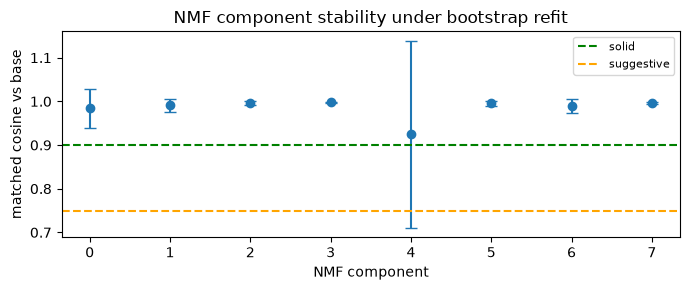

In [23]:
print(f"base fit: NMF k={nmf.n_components_}  (the `nmf` from the cell above)")
cos, ari = nmf_stability(nmf, Xs)

dom_n = pd.Series(nmf.transform(Xs).argmax(1)).value_counts().reindex(range(nmf.n_components_), fill_value=0)
top3  = [', '.join(pd.Series(nmf.components_[c], index=nmf_cols)
                   .nlargest(3).index) for c in range(nmf.n_components_)]
stab = pd.DataFrame({'n': dom_n.values, 'top_codes': top3,
                     'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3),
                     'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75],
                            ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"\nbootstrap ARI of argmax labels: mean {ari.mean():.3f}  sd {ari.std():.3f}  "
      f"(Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)")

plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green',  label='solid')
plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base')
plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit')
plt.tight_layout(); plt.show()

In [24]:
COHORT = 'chestpain'
# Persist the NMF components next to the .npz: n, top tokens with concept ids, a signature, and the names you give them.
# Part B of this notebook loads this file (COMP_JSON) for the component names. Workflow: run once -> copy the printed DESCR block
# (or paste names from Claude) into DESCR below -> run again. Components not listed in DESCR keep the names already saved
# in the file, as long as their top-5 tokens are unchanged.
import json, hashlib, os
CARD, RX, NONC, BG = 'cardiac workup', 'drug domain', 'non-cardiac explanation', 'background'
DESCR = {
    0: dict(name='acute / ED cardiac workup (troponin, ECG, chest X-ray, D-dimer, CBC / CMP / BMP, magnesium)', group=CARD),
    1: dict(name="women's health and genitourinary (gyn exam, infectious-agent tests, cytology, pregnancy test, urine culture, transvaginal echo)", group=BG),
    2: dict(name='outpatient cardiometabolic / preventive check-up (general exam, lipids, HbA1c, periodic preventive visit, ECG, hypertension, immunization, cancer screening)', group=CARD),
    3: dict(name='acute-illness prescriptions (steroids, antibiotics, NSAIDs, nasal steroid, muscle relaxant)', group=RX),
    4: dict(name='GI endoscopy / peri-procedural care (sedation and anesthesia drugs, ondansetron, dexamethasone, ketorolac, surgical pathology, GERD, CT)', group=NONC),
    5: dict(name='musculoskeletal / physical therapy (PT, manual therapy, chiropractic; low back, neck, shoulder pain)', group=BG),
    6: dict(name='nutrition and endocrine labs (vitamin B12 / D, iron, ferritin, folate, free T4, TSH, testosterone)', group=BG),
    7: dict(name='acute respiratory infection (cough, URI, pharyngitis, COVID-19, antigen tests, sinusitis)', group=NONC),
}
DESCR_K = len(DESCR)   # the k these names were written for; with another k they are skipped (re-fill after reading the top tokens)

k_j       = nmf.n_components_
if k_j != DESCR_K:
    print(f"k={k_j}, but the names in DESCR are for k={DESCR_K}: skipped"); DESCR = {}
NPZ_J     = f"nmf_k{k_j}_{TAG}.npz"
JSON_PATH = f"nmf_k{k_j}_{TAG}_components.json"
TOP_J     = 10

Hj     = pd.DataFrame(nmf.components_, columns=nmf_cols)
lab_j  = nmf.transform(Xs).argmax(1)
meta_j = events.drop_duplicates('tag').set_index('tag')
old    = json.load(open(JSON_PATH))['components'] if os.path.exists(JSON_PATH) else {}

comps = {}
for c in range(k_j):
    row = Hj.iloc[c]
    sig = list(row.nlargest(5).index)
    toks = []
    for t, v in row.nlargest(TOP_J).items():
        m = meta_j.loc[t]
        toks.append(dict(token=t, concept_id=int(m.concept_id) if pd.notna(m.concept_id) else None,
                         concept_name=str(m.concept_name), vocabulary_id=str(m.vocabulary_id), concept_code=str(m.concept_code),
                         loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
    n    = int((lab_j == c).sum())
    keep = old.get(str(c), {})
    keep = keep if set(keep.get('signature', [])) == set(sig) else {}            # saved names only survive if the component is unchanged
    d    = DESCR.get(c, {})
    comps[str(c)] = dict(n=n, pct=round(n / len(lab_j) * 100, 2), signature=sig,
                         name=d.get('name', keep.get('name')), group=d.get('group', keep.get('group')),
                         status=d.get('status', keep.get('status')), top_tokens=toks)

out = dict(cohort=COHORT, k=int(k_j), npz=NPZ_J,
           npz_sha256=hashlib.sha256(open(NPZ_J, 'rb').read()).hexdigest() if os.path.exists(NPZ_J) else None,
           n_patients=int(len(lab_j)), components=comps)
with open(JSON_PATH, 'w') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(f"saved {JSON_PATH}  (k={k_j}, {len(lab_j):,} patients)\n")

print(f"{'comp':>4} {'n':>6} {'%':>5}  name  |  top tokens")
for c, d in comps.items():
    print(f"{c:>4} {d['n']:>6} {d['pct']:5.1f}  {d['name'] or '(unnamed)'}  |  " + ', '.join(t['token'].split('__')[0] for t in d['top_tokens'][:4]))
print("\n# paste-ready DESCR (edit name / group / status, then re-run this cell):")
print("DESCR = {")
for c, d in comps.items():
    extra = f", status={d['status']!r}" if d['status'] else ''
    print(f"    {c}: dict(name={d['name']!r}, group={d['group']!r}{extra}),")
print("}")


saved nmf_k8_chestpain_full_k8_components.json  (k=8, 139,416 patients)

comp      n     %  name  |  top tokens
   0  20392  14.6  acute / ED cardiac workup (troponin, ECG, chest X-ray, D-dimer, CBC / CMP / BMP, magnesium)  |  troponin_quantitativ, electrocardiogram_ro, electrocardiogram_ro, radiologic_examinati
   1  13487   9.7  women's health and genitourinary (gyn exam, infectious-agent tests, cytology, pregnancy test, urine culture, transvaginal echo)  |  gynecologic_examinat, infectious_agent_det, infectious_agent_det, urine_pregnancy_test
   2  44564  32.0  outpatient cardiometabolic / preventive check-up (general exam, lipids, HbA1c, periodic preventive visit, ECG, hypertension, immunization, cancer screening)  |  general_examination, lipid_panel_this_pan, periodic_comprehensi, venipuncture_for_blo
   3  20165  14.5  acute-illness prescriptions (steroids, antibiotics, NSAIDs, nasal steroid, muscle relaxant)  |  21_methylprednisolon, amoxicillin_875_mg_c, 6_azithromycin_250_m, p

# Part B · Day 3 — sequence motifs inside the NMF bundles

In [25]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
acute_upper_respirat__disorder__257011 -> impacted_cerumen__disorder__374375 -> removal_impacted_cer__cpt4__42627985 -> infectious_agent_ant__cpt4__2213181 -> umbilical_hernia__disorder__4245842 -> periodic_comprehensi__cpt4__2514528 -> general_examination___procedure__4036803 -> incisional_hernia__disorder__198464 -> palpitations__clinical_finding__315078 -> abnormal_findings_di__clinical_finding__435081 -> cardiovascular_stres__cpt4__2313820 -> cardiovascular_stres__cpt4__2313822

median sequence length: 167


### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** They were the most common tokens in v1 and
   made every motif list a chain of pharmacy / office / ED visits. Dropping them removes that
   care-setting bias; it also removes the `ed_visit` tag, so any motif that depended on "went to the
   ED" is invisible here by construction.

## 1 · PrefixSpan, implemented


In [26]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in sorted(set(seq)):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **NMF components of
`Day1_nmf_v3`** (concept-level tokens, visits pruned; `K` is set in the NMF cell below).

What the v2 loadings showed, so the motifs below can be read against it:

- **c3 acute / ED workup** owns `troponin` (62%, rank 1); **c0 outpatient cardiometabolic workup** owns
  `ekg`, `stress_test`, `hba1c`, `t2dm`. `cad` and `coronary_angio` are split between the two.
- **No anxiety / panic bundle exists**: `anxiety` is spread 10-22% over c0, c2, c3, c7;
  `panic_attack` sits in c3 (28%) and c7 (27%). `ssri` / `benzodiazepine` load on the prescription
  bundle c1, but so do `beta_blocker` and `statin`.
- **c4** is the GI / screening bundle that owns `gerd`.

Day 3 asks what order those codes come in, per component.


In [27]:
# Part B starts from the NMF fitted in Part A (same events, same prevalence floor, same anchor drop): no refit, no cache file.
K    = nmf.n_components_
H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
lab  = pd.Series(nmf.transform(Xs).argmax(1), index=X.index)
comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

CARD, RX, NONC, BG = 'cardiac workup', 'drug domain', 'non-cardiac explanation', 'background'
COMP = {}                                                     # auto-names from the top tokens; real names come from the components JSON below
for c in range(K):
    top = H.iloc[c].idxmax()
    COMP[c] = (top[:20], f'c{c}: ' + ', '.join(H.iloc[c].nlargest(3).index.str.split('__').str[0]), BG)
# Names from the components JSON written by the last cell of Part A: override COMP for every component whose top-5 tokens still match
# (>= 4 of 5); otherwise the auto-name is kept and a warning is printed. Point COMP_JSON at another file to reuse it.
import json
COMP_JSON = f"nmf_k{K}_{TAG}_components.json"
if os.path.exists(COMP_JSON):
    J = json.load(open(COMP_JSON))['components']
    for c in range(K):
        j = J.get(str(c))
        if not j or not j.get('name'):
            continue
        if len(set(j['signature']) & set(H.iloc[c].nlargest(5).index)) < 4:
            print(f"WARNING c{c}: top tokens in {COMP_JSON} differ from this NMF, its name is ignored")
            continue
        COMP[c] = (COMP[c][0], j['name'], j.get('group') or COMP[c][2]) + ((j.get('status') or COMP[c][3],) if len(COMP[c]) > 3 else ())
    print(f"component names loaded from {COMP_JSON}")
else:
    print(f"{COMP_JSON} not found: components are auto-named (name them in DESCR in the last cell of Part A)")
print("top tokens per component:")
for c in range(K):
    print(f"  c{c}:", ', '.join(H.iloc[c].nlargest(4).index.str.slice(0, 32)))

print(f"{'comp':>4} {'n':>6} {'%':>5}  {'group':<24} name")
for c, v in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>6} {n / len(comp) * 100:5.1f}  {v[2]:<24} {v[1]}")


component names loaded from nmf_k8_chestpain_full_k8_components.json
top tokens per component:
  c0: troponin_quantitativ__cpt4__2212, electrocardiogram_ro__cpt4__2313, electrocardiogram_ro__cpt4__2313, radiologic_examinati__cpt4__7250
  c1: gynecologic_examinat__procedure_, infectious_agent_det__cpt4__2213, infectious_agent_det__cpt4__2213, urine_pregnancy_test__procedure_
  c2: general_examination___procedure_, lipid_panel_this_pan__cpt4__2212, periodic_comprehensi__cpt4__2514, venipuncture_for_blo__procedure_
  c3: 21_methylprednisolon__clinical_p, amoxicillin_875_mg_c__clinical_d, 6_azithromycin_250_m__clinical_p, prednisone_20_mg_ora__clinical_d
  c4: ondansetron_injectio__clinical_d, fentanyl_005_mgml_in__branded_dr, propofol_injection__clinical_dru, midazolam_injectable__branded_dr
  c5: therapeutic_procedur__cpt4__2314, manual_therapy_techn__cpt4__2314, therapeutic_activiti__cpt4__2314, low_back_pain__clinical_finding_
  c6: vitamin_b12_measurem__procedure_, vitamin_d_25hydroxy

In [28]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values(['lift', 'pattern'], ascending=[False, True]).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.10, max_cand=60, n_out=1500, max_in=3000, seed=0, n_jobs=None):
    """All components in parallel (they are independent); largest first so no big job starts last.
    Each component is mined on a random sample of at most `max_in` of its patients (PrefixSpan is
    pure Python; a 30,000-patient component would take hours). Raise max_in once you know the runtime."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    order  = sorted(COMP, key=lambda c: -int((comp == c).sum()))
    jobs   = []
    for c in order:
        idx_in  = np.flatnonzero(comp == c)
        idx_in  = np.random.default_rng(seed).choice(idx_in, min(max_in, len(idx_in)), replace=False)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(order, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 6% components entirely
motifs = component_motifs()
for c, (_, name, role) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{role}]: {name}  (n={(comp == c).sum()}, mined on {min(3000, (comp == c).sum())})")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done 3 out of 8 | elapsed:  1.7min remaining:  2.8min
[Parallel(n_jobs=8)]: Done 5 out of 8 | elapsed:  5.8min remaining:  3.5min



===== component 0 [cardiac workup]: acute / ED cardiac workup (troponin, ECG, chest X-ray, D-dimer, CBC / CMP / BMP, magnesium)  (n=20392, mined on 3000)


[Parallel(n_jobs=8)]: Done 8 out of 8 | elapsed: 60.6min finished


,pattern,sup_in,sup_out,lift
0,chest_pain__clinical_finding__77670 -> radiolo...,0.482,0.139,3.3
1,chest_pain__clinical_finding__77670 -> radiolo...,0.520,0.154,3.2
2,radiologic_examinati__cpt4__725068 -> electroc...,0.540,0.161,3.2
3,chest_pain__clinical_finding__77670 -> radiolo...,0.503,0.158,3.1



===== component 1 [background]: women's health and genitourinary (gyn exam, infectious-agent tests, cytology, pregnancy test, urine culture, transvaginal echo)  (n=13487, mined on 3000)


...

,pattern,sup_in,sup_out,lift
0,therapeutic_procedur__cpt4__2314284 -> therape...,0.443,0.066,6.0
1,therapeutic_activiti__cpt4__2314294 -> therape...,0.439,0.066,5.9
2,manual_therapy_techn__cpt4__2314290 -> manual_...,0.442,0.068,5.8
3,therapeutic_activiti__cpt4__2314294 -> therape...,0.465,0.072,5.8



===== component 6 [background]: nutrition and endocrine labs (vitamin B12 / D, iron, ferritin, folate, free T4, TSH, testosterone)  (n=10321, mined on 3000)


,pattern,sup_in,sup_out,lift
0,lipid_panel_this_pan__cpt4__2212095 -> vitamin...,0.624,0.115,5.1
1,lipid_panel_this_pan__cpt4__2212095 -> vitamin...,0.722,0.137,5.0
2,vitamin_d_25hydroxy___procedure__4007831 -> vi...,0.667,0.125,5.0
3,vitamin_d_25hydroxy___procedure__4007831 -> vi...,0.615,0.125,4.6



===== component 7 [non-cardiac explanation]: acute respiratory infection (cough, URI, pharyngitis, COVID-19, antigen tests, sinusitis)  (n=12063, mined on 3000)


,pattern,sup_in,sup_out,lift
0,cough__clinical_finding__254761 -> comprehensi...,0.314,0.165,1.9
1,cough__clinical_finding__254761 -> venipunctur...,0.299,0.152,1.9
2,cough__clinical_finding__254761 -> venipunctur...,0.298,0.154,1.9
3,cough__clinical_finding__254761 -> venipunctur...,0.294,0.155,1.8


In [29]:
# Held-out pass rate, family clustering and same-day flag (the table below reads them). Computed in motif_robustness/hybrid.py, nothing is shown here.
import sys, time
sys.path.insert(0, "../repr_learn_letrozole")          # shared helpers, not copied
from motif_robustness.preprocess import build_patient_seqs
from motif_robustness.hybrid import add_heldout_chestpain

REL_SUP        = 0.10                     # component_motifs() default support floor
HO_SEEDS       = tuple(range(101, 121))   # 20 splits; both directions are scored -> 40 runs
HO_MIN_OR      = 2.0                      # lower 95% bound of the odds ratio on the held-out half
HO_MIN_RATE_LO = 0.70                     # family pass rate (lower Wilson bound) needed to call a motif stable
FAM_DIST       = 0.2
SAME_DAY_RATIO = 0.5                      # strict-date support / tie-ordered support below this = same-day bundle

_p, _ps = build_patient_seqs(events)      # same dedup / collapse rules as eo.sequences, but keeps the dates
assert _p == pids and all(_ps[p].tokens == s for p, s in zip(pids, db)), "dated sequences differ from db"
patseqs = [_ps[p] for p in pids]
n_in = {c: int((comp == c).sum()) for c in COMP}

t0 = time.perf_counter()
hyb, ho_runs = add_heldout_chestpain(motifs, comp, patseqs, rel_sup=REL_SUP, ho_seeds=HO_SEEDS, ho_min_or=HO_MIN_OR,
                                     ho_min_rate_lo=HO_MIN_RATE_LO, fam_dist=FAM_DIST, same_day_ratio=SAME_DAY_RATIO)
print(f"held-out pass rate: {(time.perf_counter() - t0):.0f} s")


held-out pass rate: 23 s


Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c3** read as a workup path (troponin, EKG, imaging, angiography, in that order) and does
  **c0** read as a slower outpatient path (EKG, stress test, labs)?
- Do `anxiety` / `panic_attack` show up as a motif *before* troponin in **c3**, or only after it?
  Without visits, a "panic in the ED" story has to be carried by the workup codes alone.
- Do the background bundles (c2, c5, c6, c7) stay generic?

### A second lens: the Day 1 psych / cardiac probe

`chest_pain_labels()` is a direct rule-based split built from corroborating co-evidence. It is a
probe, not the structure: the labels come from `PSYCH_TAGS` / `CARDIAC_TAGS`, so a motif made of
those same tags partly rediscovers the label rule. Mined on a random 5,000-patient sample, since
every candidate is scanned against every sequence.


In [30]:
weak = eo.chest_pain_labels(events)
wl   = weak.set_index('person_id').chest_pain_label

# All patients here have chest_pain by cohort construction, so no filtering needed. LOCAL mining on a
# fixed random sample: candidates x sequences scans are the cost on a cohort this size.
rng   = np.random.default_rng(0)
samp  = rng.choice(len(db), min(5_000, len(db)), replace=False)
db_s  = [db[i] for i in samp]
y_s   = np.array([wl.get(pids[i], 'unlabelled') for i in samp])
print("sampled patients:", len(db_s),
      "  labelled:", int((y_s != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_s, return_counts=True))))

pats_cp = prefixspan(db_s, max(3, int(0.08 * len(db_s))), max_len=4)
C_cp = [tuple(p) for p in pats_cp[pats_cp.pattern.map(len) >= 3]
        .sort_values(['support', 'pattern'], ascending=[False, True]).head(60).pattern]

for g in ['psych', 'cardiac']:
    print(f"\n=== {g} evidence")
    display(discriminative(y_s == g, C_cp, sequences_db=db_s, min_in=0.10).head(6))


chest_pain patients: 139416   labelled: 65235   both-evidence (dropped): 37617   no-evidence (dropped): 36564
sampled patients: 5000   labelled: 2402    {np.str_('cardiac'): np.int64(1419), np.str_('psych'): np.int64(983), np.str_('unlabelled'): np.int64(2598)}

=== psych evidence


,pattern,sup_in,sup_out,lift
0,chest_pain__clinical_finding__77670 -> venipun...,0.378,0.439,0.9
1,general_examination___procedure__4036803 -> ve...,0.360,0.402,0.9
2,venipuncture_for_blo__procedure__4102442 -> li...,0.369,0.435,0.9
3,chest_pain__clinical_finding__77670 -> lipid_p...,0.295,0.391,0.8
4,chest_pain__clinical_finding__77670 -> lipid_p...,0.314,0.383,0.8
5,chest_pain__clinical_finding__77670 -> venipun...,0.340,0.444,0.8



=== cardiac evidence


,pattern,sup_in,sup_out,lift
0,chest_pain__clinical_finding__77670 -> compreh...,0.579,0.440,1.3
1,chest_pain__clinical_finding__77670 -> venipun...,0.497,0.402,1.2
2,chest_pain__clinical_finding__77670 -> venipun...,0.509,0.416,1.2
3,chest_pain__clinical_finding__77670 -> venipun...,0.431,0.345,1.2
4,complete_blood_count__procedure__4319466 -> co...,0.470,0.390,1.2
5,complete_blood_count__procedure__4319466 -> ve...,0.445,0.367,1.2


**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A the same week" versus "A two years before B,"
which is the actual dx_9487 discriminator: is the anxiety history old and unrelated, or did
a cardiac workup follow within days. Allen's interval algebra defines 13 relations; for
point events on dates, a **signed gap** carries most of the value.

### 3b · Does psych evidence come before or after troponin?

Motif mining only surfaces patterns above a support floor, and psychiatric care is a minority inside
every bundle, so it can miss exactly this question. This asks it directly, with no floor: for each
patient with both, the days from their first psych evidence to their first troponin.

- **Psych evidence** = an anxiety or panic diagnosis, or a psychiatric evaluation / psychotherapy code
  (`psych_eval_therapy`). SSRIs and benzodiazepines are left out: they are prescribed for many reasons.
- Positive = psych evidence **first**, then troponin. Negative = troponin first.
- Patients with psych evidence and no troponin are not in this comparison (no workup in the data).
- Only meaningful where history covers the earlier event, as in section 3.


,n,psych first %,same day %,troponin first %,median days
ALL (psych + troponin),27046.0,57.2,7.4,35.4,108.0
c0 acute / ED cardiac workup (troponi,6323.0,48.2,11.8,40.0,0.0
c2 outpatient cardiometabolic / preve,5041.0,55.9,7.0,37.2,98.0
c1 women's health and genitourinary (,3485.0,62.8,5.6,31.6,207.0
c6 nutrition and endocrine labs (vita,2679.0,60.2,6.3,33.4,159.0
c3 acute-illness prescriptions (stero,2576.0,58.6,8.0,33.3,147.0
c5 musculoskeletal / physical therapy,2338.0,63.6,4.7,31.7,246.0
c4 GI endoscopy / peri-procedural car,2303.0,60.4,3.8,35.8,144.0
c7 acute respiratory infection (cough,2301.0,62.1,5.6,32.4,201.0


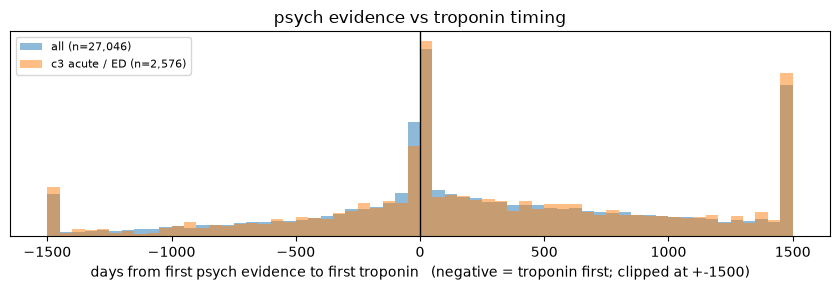

In [31]:
PSYCH = ['anxiety', 'panic_attack', 'psych_eval_therapy']
ev    = events[['person_id', 'event_date', 'concept_id', 'groups']]                  # no copy of the full frame
first = lambda tags: ev.loc[eo.group_mask(ev, tags)].groupby('person_id').event_date.min()

both = pd.concat([first(PSYCH).rename('psych'), first(['troponin']).rename('trop')], axis=1).dropna()
both['days_psych_to_trop'] = (both.trop - both.psych).dt.days
both['bundle'] = pd.Series(comp, index=pids).reindex(both.index)
both = both[both.bundle >= 0]                                   # drop patients with no assigned bundle

def timing(d):
    g = d.days_psych_to_trop
    return pd.Series({'n': len(d), 'psych first %': round((g > 0).mean() * 100, 1),
                      'same day %': round((g == 0).mean() * 100, 1),
                      'troponin first %': round((g < 0).mean() * 100, 1),
                      'median days': g.median()})

tab = both.groupby('bundle').apply(timing)
tab.index = [f"c{int(b)} {COMP[int(b)][1][:34]}" for b in tab.index]
tab.loc['ALL (psych + troponin)'] = timing(both)
display(tab.sort_values('n', ascending=False))

c3d = both[both.bundle == 3].days_psych_to_trop
plt.figure(figsize=(8.5, 3))
plt.hist(both.days_psych_to_trop.clip(-1500, 1500), bins=60, alpha=.5, density=True, label=f"all (n={len(both):,})")
plt.hist(c3d.clip(-1500, 1500), bins=60, alpha=.5, density=True, label=f"c3 acute / ED (n={len(c3d):,})")
plt.axvline(0, c='k', lw=1); plt.yticks([])
plt.xlabel('days from first psych evidence to first troponin   (negative = troponin first; clipped at +-1500)')
plt.legend(fontsize=8); plt.title('psych evidence vs troponin timing')
plt.tight_layout(); plt.show()


## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is the closest thing
to a chest-pain triage flowchart, but derived from observed transitions rather than a
guideline document — Ethos has no chest-pain ruleset to start from, so the agreed method is
to start from the data and check clinical plausibility afterwards.

In [32]:
import networkx as nx

FOCUS = {'chest_pain', 'ekg', 'troponin', 'stress_test',
         'coronary_angio', 'beta_blocker', 'statin', 'cad',
         'anxiety', 'panic_attack', 'ssri', 'benzodiazepine',
         'gerd', 'costochondritis'}

# the graph is about curated clinical steps: relabel each concept token by its group, drop uncurated ones, collapse repeats
import itertools
_tg = events.drop_duplicates('tag').dropna(subset=['groups']).set_index('tag')['groups'].astype(str).str.split('|').to_dict()   # token -> ALL its groups
gseqs = {p: [g for g, _ in itertools.groupby(g for t in seqs[p] for g in _tg.get(t, ()))] for p in pids}
db_cp = [[c for c in gseqs[p] if c in FOCUS] for p in pids if 'chest_pain' in gseqs[p]]
print(f"{len(db_cp)} chest pain patients")

cnt = collections.Counter()
for s in db_cp:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_cp))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")


139416 chest pain patients
13 nodes, 79 edges


### Trajectory graph on a time axis
x = median days from the first chest pain to the first time the patient has that group (negative = before it), y = the component group that owns the tag's NMF loading. Nodes in a lane are staggered by x, so labels cannot overlap. The cell above only builds the transitions (`G`).

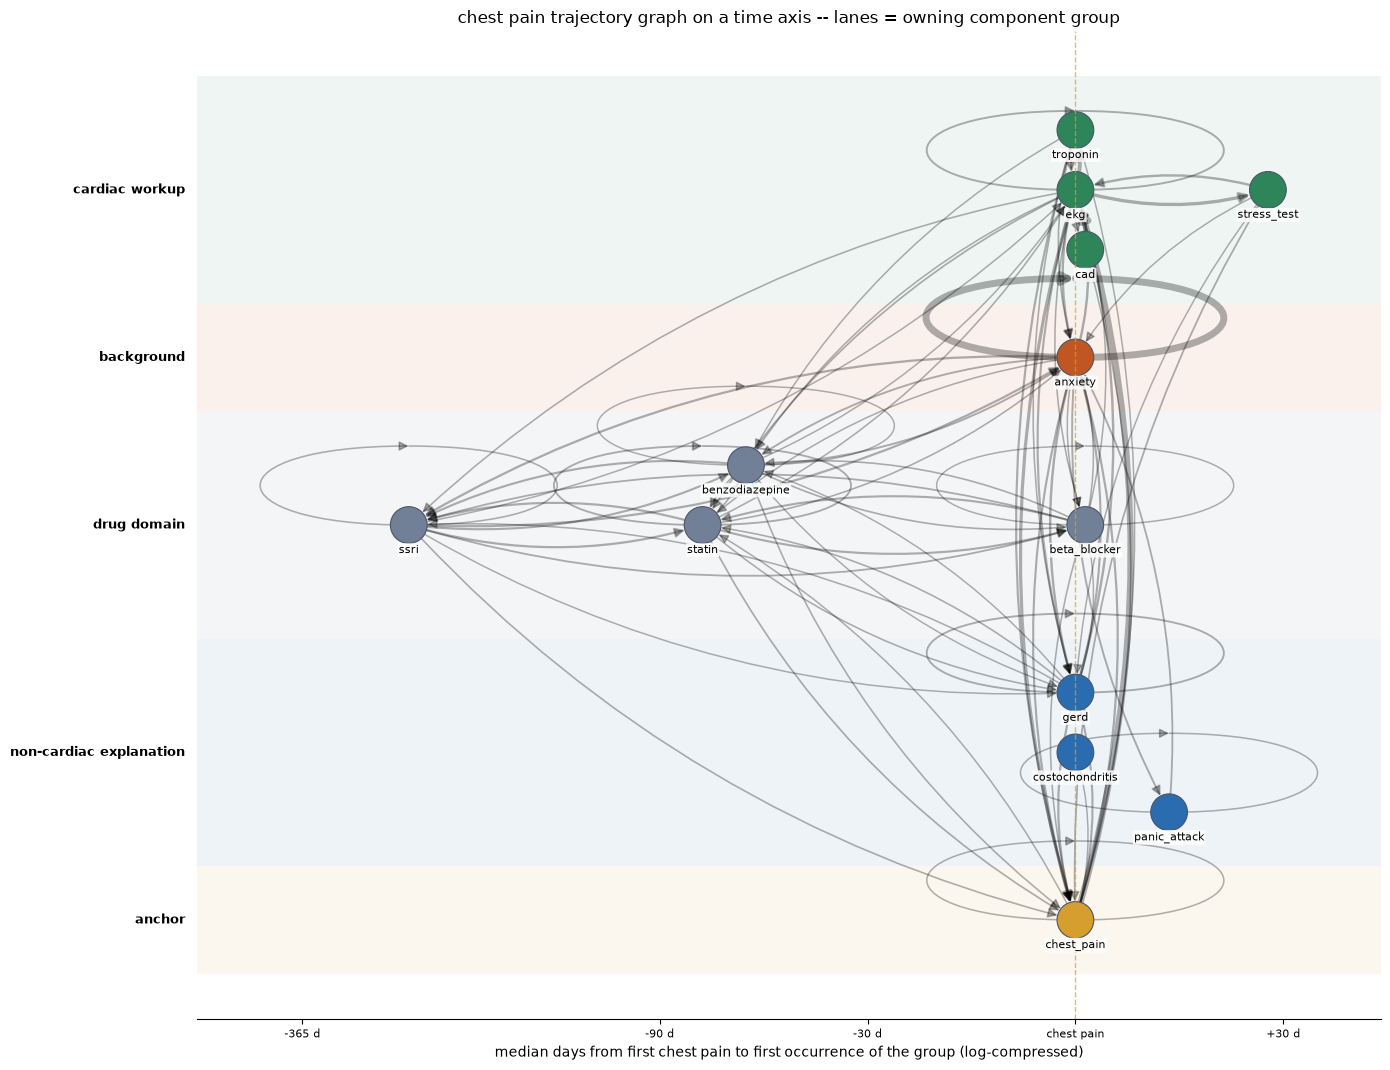

{'cardiac workup': 4, 'background': 1, 'drug domain': 4, 'non-cardiac explanation': 3, 'anchor': 1} nodes per lane; 0 without timing


In [33]:
# Trajectory graph on a time axis: x = median days from the patient's first chest pain to the first time the patient has that group
# (log-compressed, 0 = chest pain), y = the component group that owns the tag's NMF loading. Nodes in one lane are staggered by x, so labels cannot overlap.
# Edges are the transitions in G (cell above). Needs the graph cell above and the dated sequences (patseqs) from the hybrid section.
ANCHOR      = 'chest_pain'
ANCHOR_NAME = ANCHOR.replace('_', ' ')
MIN_N       = 20                                                   # fewer patients with both -> no timing, node parked at the right edge
SLOT, LABEL_IN = 1.0, 1.15                                          # vertical stagger step (y units), room one label needs on the x axis (inches)

_nodes  = set(G.nodes())
_have   = [i for i, p in enumerate(pids) if ANCHOR in gseqs[p]]     # the cohort of the graph
_first  = {n: [] for n in _nodes}
_a_tok  = {t for t, gs in _tg.items() if ANCHOR in gs}
for i in _have:
    ps = patseqs[i]
    a0 = min((ps.dpos[t][0] for t in _a_tok if t in ps.dpos), default=None)
    if a0 is None:
        continue
    best = {}
    for t, dl in ps.dpos.items():
        for g in _tg.get(t, ()):
            if g in _nodes and (g not in best or dl[0] < best[g]):
                best[g] = dl[0]
    for g, d in best.items():
        _first[g].append(d - a0)
med = {g: float(np.median(v)) for g, v in _first.items() if len(v) >= MIN_N}
med[ANCHOR] = 0.0

Hg_    = Hg if 'Hg' in globals() else eo.group_loadings(H, events)
comps_ = list(dict.fromkeys(v[2] for v in COMP.values()))           # component groups, in COMP order
def owner_lane(g):
    if g == ANCHOR:
        return 'anchor'
    if g not in Hg_.columns or Hg_[g].sum() == 0:
        return 'not in NMF'
    share = {l: Hg_.loc[[k for k, v in COMP.items() if v[2] == l], g].sum() / Hg_[g].sum() for l in comps_}
    return max(share, key=share.get)
lane_of  = {n: owner_lane(n) for n in _nodes}
LANES    = [l for l in comps_ + ['anchor', 'not in NMF'] if l in set(lane_of.values())]
_pal     = ['#2f855a', '#c05621', '#718096', '#2b6cb0', '#b83280', '#b7791f']
LANE_COL = {**{l: _pal[i % len(_pal)] for i, l in enumerate(comps_)}, 'anchor': '#d69e2e', 'not in NMF': '#a0aec0', **globals().get('GCOL', {})}

tf = lambda d: np.sign(d) * np.log1p(np.abs(d) / 30)                # days -> compressed axis, 0 stays 0
xs = {g: tf(m) for g, m in med.items() if g in _nodes}
x_park = (max(xs.values()) if xs else 0) + 1.4
_all_x = list(xs.values()) + ([x_park] if any(n not in xs for n in _nodes) else [])
MIN_DX = LABEL_IN * (max(_all_x) - min(_all_x) + 1) / 12.0           # x units that fit one label on a 14 in wide figure
order  = [0] + [s * k for k in range(1, 13) for s in (1, -1)]
slot_of, lane_k = {}, {}
for l in LANES:
    members = sorted((n for n in _nodes if lane_of[n] == l), key=lambda n: (xs.get(n, x_park), n))
    last = {}                                                      # slot -> x of the last node placed there
    for n in members:
        x = xs.get(n, x_park)
        k = next(k for k in order if x - last.get(k, -1e9) >= MIN_DX)
        last[k] = x; slot_of[n] = (l, k, x)
    lane_k[l] = max((abs(k) for (ll, k, _) in slot_of.values() if ll == l), default=0)
heights = {l: 2 * lane_k[l] * SLOT + 1.8 for l in LANES}            # a lane is as tall as its stagger needs
centers, y_top = {}, 0.0
for l in LANES:
    centers[l] = y_top - heights[l] / 2; y_top -= heights[l]
pos_t = {n: (x, centers[l] + k * SLOT) for n, (l, k, x) in slot_of.items()}

fig, ax = plt.subplots(figsize=(14, max(5, 0.6 * (-y_top) + 1.8)))
for l in LANES:
    ax.axhspan(centers[l] - heights[l] / 2, centers[l] + heights[l] / 2, color=LANE_COL.get(l, '#e2e8f0'), alpha=.08, lw=0)
    ax.text(-0.01, centers[l], l, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold')
w = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_edges(G, pos_t, ax=ax, width=1 + 4 * w / w.max(), alpha=.3, arrowsize=14, node_size=700, connectionstyle='arc3,rad=0.15')
nx.draw_networkx_nodes(G, pos_t, ax=ax, node_size=700, node_color=[LANE_COL.get(lane_of[n], '#e2e8f0') for n in G.nodes()], edgecolors='#4a5568', linewidths=.8)
nx.draw_networkx_labels(G, {n: (x, y - 0.42) for n, (x, y) in pos_t.items()}, ax=ax, font_size=8,
                        bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.tick_params(axis='x', bottom=True, labelbottom=True)              # networkx hides the ticks
tick_d = [-365, -90, -30, 0, 30, 90, 365, 730]
ax.set_xticks([tf(d) for d in tick_d]); ax.set_xticklabels([f"{d:+d} d" if d else ANCHOR_NAME for d in tick_d], fontsize=8)
ax.axvline(0, color='#d69e2e', lw=1, ls='--', alpha=.7)
if any(n not in xs for n in _nodes):
    ax.text(x_park, 0.3, f'timing n<{MIN_N}', ha='center', fontsize=8, color='#718096')
ax.set_yticks([]); ax.spines[['left', 'right', 'top']].set_visible(False)
ax.set_xlabel(f"median days from first {ANCHOR_NAME} to first occurrence of the group (log-compressed)")
ax.set_title(f'{ANCHOR_NAME} trajectory graph on a time axis -- lanes = owning component group')
plt.margins(x=.06); plt.tight_layout(); plt.show()
print({l: int(sum(1 for n in _nodes if lane_of[n] == l)) for l in LANES}, "nodes per lane;", sum(1 for n in _nodes if n not in xs), "without timing")


**How to read it.** Left to right is time: each tag sits at the median number of days between the patient's first chest pain and the first time they have that tag (log-compressed; left = before chest pain, right = after, the dashed line is chest pain). Each row (lane) is the NMF component role that owns most of the tag's loading (cardiac workup, drug domain, non-cardiac explanation or background, as set in `COMP`). `chest_pain` has its own lane because it is the cohort anchor and not in the NMF; a tag too rare to reach the NMF goes to a "not in NMF" lane. Tags inside a lane are staggered up and down only so the labels do not overlap: the vertical offset has no meaning. A tag with fewer than 20 patients who have both it and chest pain has no timing and is parked at the right edge. Positions use the *first* occurrence, so a tag that repeats (ECG, statin) can look earlier than the episode next to chest pain. A lane is a loading share, not a diagnosis. Arrows are the observed transitions between consecutive curated steps; thicker = more patients.

Two arms should be visible out of `chest_pain`: one through troponin, stress test,
angiography and statins; the other through anxiety, panic_attack, ssri and benzodiazepine.
Whichever arm dominates numerically is the answer to the working hypothesis — let the graph
say which, rather than assuming.

## Carry forward

A motif catalog for dx_9487 triage, obtained without a foundation model.

## 5 · Final table — top chest pain sequences and where they rank
Per NMF bundle: the highest-lift ordered patterns that contain a chest pain step, each with its rank among the bundle's scored top patterns, and under every top entity the median timing against the first chest pain. A post-filter of the scored candidates, so every score and verdict is the one computed above. Writes its own xlsx.

In [34]:
COHORT = 'chestpain'
# ANCHOR-FOCUSED view of the final table (additional; the table above is untouched): per bundle, the top-TOPK_ANCHOR scored ordered patterns that contain a chest_pain step,
# with the position of that step (k of n). Same scores / verdicts as the table above (post-filter of hyb, no re-mining). Own xlsx file; Triage / literature / PMIDs left empty.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"final_table_{COHORT}_k{K}_{VARIANT}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

ANCHOR      = 'chest_pain'                                                    # cohort anchor group (codesets.yaml)
ANCHOR_NAME = ANCHOR.replace('_', ' ')
ANCHOR_TOK  = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])    # every concept-level token that belongs to the anchor group
TOPK_ANCHOR = 3                                                       # anchor patterns per bundle (highest lift first)

def has_anchor(pattern):
    return any(t in ANCHOR_TOK for t in pattern.split(' -> '))

_a0 = {}
def offset_text(c, members, t, min_n=20):
    """Median days from each patient's first {ANCHOR} step to their first occurrence of token t (negative = t came first), over the bundle's patients who have both."""
    if c not in _a0:                                                       # first anchor day per member, computed once per bundle
        _a0[c] = np.array([min((patseqs[i].dpos[x][0] for x in ANCHOR_TOK if x in patseqs[i].dpos), default=np.nan) for i in members])
    td = np.array([patseqs[i].dpos[t][0] if t in patseqs[i].dpos else np.nan for i in members])
    g  = (td - _a0[c])[~np.isnan(td - _a0[c])]
    if len(g) < min_n:
        return f"\n    vs first {ANCHOR_NAME}: too few patients with both (n={len(g)})"
    med = int(np.median(g))
    when = "same day as" if med == 0 else f"{abs(med):,} d {'before' if med < 0 else 'after'}"
    return f"\n    median {when} first {ANCHOR_NAME} ({(g < 0).mean():.0%} of them before)"

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care when chest pain is present', "Position in the bundle's scored top patterns (by lift · by support)", 'Share of group with pattern', 'Share of everyone else with pattern', 'Held-out pass rate (family, 40 splits)', 'Holds up on held-out halves?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion (Manual RUW / Routine / Unclear)', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 13)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle){offset_text(c, members, t)}" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} · {COMP[c][1]}", f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    pool  = hyb.get(c)
    pool  = pool if pool is not None and len(pool) else None
    if pool is not None:
        pool = pool.assign(rk_lift=np.arange(1, len(pool) + 1), rk_sup=pool.sup_in.rank(ascending=False, method='min').astype(int))   # hyb[c] is lift-sorted
        has  = pool.pattern.map(has_anchor)
    d     = pool[has].head(TOPK_ANCHOR) if pool is not None else None
    head[1] += f"\n{int(has.sum()) if pool is not None else 0} of {len(pool) if pool is not None else 0} scored patterns contain {ANCHOR_NAME}"
    if d is None or not len(d):
        table.append((c, head + ['', f"no scored pattern contains {ANCHOR_NAME} (bundle has {len(pool) if pool is not None else 0} scored patterns)"] + [''] * (len(HEAD) - 5)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        ok = r.fam_holdout_rate_lo >= HO_MIN_RATE_LO
        verdict = 'Unstable' if not ok else ('Suggestive' if r.same_day_bundle else 'Solid')
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), f"{int(r.rk_lift)} of {len(pool)} by lift · {int(r.rk_sup)} of {len(pool)} by support", float(r.sup_in), float(r.sup_out), float(r.fam_holdout_rate), 'Yes' if ok else 'No',
                                                     float(r.lift), verdict, '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 13}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (7, 8, 9): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 11).number_format = '0.0'
    for j in (10, 12, 14):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 15))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 22, 70, 8, 80, 22, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: fused Day 1 + Day 3 notebook, chestpain run ({VARIANT}{', +/- ' + str(WINDOW_MONTHS) + ' months around any chest pain event' if WINDOW_MONTHS else ''}), NMF k={K} on concept-level tokens, {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK_ANCHOR} highest-lift scored ordered patterns of each bundle that contain a {ANCHOR_NAME} step (any {ANCHOR_NAME} concept), from the same candidates as the main table (ordered patterns of 3+ steps, each present in >={REL_SUP:.0%} of the bundle). The second line of each n (%) cell says how many of the bundle's scored patterns contain {ANCHOR_NAME}.",
    f"Entities: under each entity, the median number of days from the patient's first {ANCHOR_NAME} step to their FIRST occurrence of that entity (before / after), over the bundle patients who have both, and the share of them for whom it came first. Repeated entities (labs, drugs) are read at their first occurrence.",
    "Position among the bundle's scored top patterns: each bundle's candidates are its 100 most frequent ordered patterns (3+ steps) that pass the support floor, scored for lift; the pattern's place in that list by lift (1 = most specific to the bundle) and by support (1 = most frequent), out of the N patterns scored. A bundle with no such pattern is shown as such, not filled.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    f"Held-out pass rate: {len(HO_SEEDS)} random 50/50 splits of the whole bundle x 2 directions = {2 * len(HO_SEEDS)} runs; a run passes if, on the half not used, support is >= {REL_SUP:.0%} and the lower 95% bound of the odds ratio vs all other patients is >= {HO_MIN_OR:g}. Near-duplicate patterns are one family (a run passes if any member does). Holds = family lower 95% bound >= {HO_MIN_RATE_LO:.0%}.",
    "Final verdict (chest pain has no bootstrap / re-test run, so the held-out result is used): Solid = holds and order shown by dates; Suggestive = holds but a same-day bundle; Unstable = does not hold.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :12]


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/final_table_chestpain_k8_full_k8.xlsx  (8 bundles, 24 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),Typical order of care when chest pain is present,Position in the bundle's scored top patterns (by lift · by support),Share of group with pattern,Share of everyone else with pattern,"Held-out pass rate (family, 40 splits)",Holds up on held-out halves?,Times as common (lift),Final verdict
0,"c0 · acute / ED cardiac workup (troponin, ECG,...","20,392 (14.6%)\n28 of 60 scored patterns conta...","1. Troponin, quantitative [CPT4 84484] (85% of...",1,Chest pain [SNOMED 29857009] → Radiologic exam...,1 of 60 by lift · 46 of 60 by support,0.482,0.139,1.0,Yes,3.3,Suggestive
1,,,,2,Chest pain [SNOMED 29857009] → Radiologic exam...,2 of 60 by lift · 28 of 60 by support,0.520,0.154,1.0,Yes,3.2,Suggestive
2,,,,3,Chest pain [SNOMED 29857009] → Radiologic exam...,4 of 60 by lift · 35 of 60 by support,0.503,0.158,1.0,Yes,3.1,Suggestive
3,c1 · women's health and genitourinary (gyn exa...,"13,487 (9.7%)\n7 of 60 scored patterns contain...",1. Gynecologic examination [SNOMED 83607001] (...,1,Venipuncture for blood test [SNOMED 28520004] ...,26 of 60 by lift · 45 of 60 by support,0.478,0.349,0.0,No,1.4,Unstable
4,,,,2,Chest pain [SNOMED 29857009] → Complete blood ...,30 of 60 by lift · 47 of 60 by support,0.475,0.357,0.0,No,1.3,Unstable
5,,,,3,Chest pain [SNOMED 29857009] → Venipuncture fo...,31 of 60 by lift · 15 of 60 by support,0.535,0.421,0.0,No,1.3,Unstable
6,c2 · outpatient cardiometabolic / preventive c...,"44,564 (32.0%)\n8 of 60 scored patterns contai...",1. General examination of patient [SNOMED 1626...,1,Chest pain [SNOMED 29857009] → Periodic compre...,5 of 60 by lift · 25 of 60 by support,0.486,0.189,1.0,Yes,2.5,Solid
7,,,,2,Chest pain [SNOMED 29857009] → General examina...,11 of 60 by lift · 43 of 60 by support,0.467,0.240,1.0,Yes,1.9,Solid
8,,,,3,Chest pain [SNOMED 29857009] → Venipuncture fo...,27 of 60 by lift · 6 of 60 by support,0.563,0.353,1.0,Yes,1.6,Solid
9,"c3 · acute-illness prescriptions (steroids, an...","20,165 (14.5%)\n19 of 60 scored patterns conta...",1. {21 (methylprednisolone 4 MG Oral… [RxNorm ...,1,"Chest pain [SNOMED 29857009] → Troponin, quant...",7 of 60 by lift · 17 of 60 by support,0.210,0.329,0.0,No,0.7,Unstable
